# How Transolver learns a PDE on any geometry: heat in a plate with a hole

This notebook builds a tiny **Transolver**, the model from Wu et al. 2024, *Transolver: A Fast Transformer Solver
for PDEs on General Geometries* ([arXiv:2402.02366](https://arxiv.org/abs/2402.02366)). It trains the model on a
problem the FNO cannot take directly, steady heat flow in an **L-shaped plate with a cooling hole**, given as a
**cloud of scattered points**, and lets you look **inside** it: every tensor, at every point of training.

Where it sits in this repository:

* The GNS notebook ([`gnn_explained.ipynb`](../../../05-graph-neural-networks/gnn/notebooks/gnn_explained.ipynb))
  learned a **time step** on particles: neighbours talk through edges.
* The FNO notebook ([`fno_explained.ipynb`](../../fno/notebooks/fno_explained.ipynb)) learned a **solution
  operator** on a **regular grid**: points talk through the FFT.
* Transolver learns a solution operator on **any set of points**: points talk through a handful of learned
  **slices** ("physical states"), using ordinary attention among the slices.

**Plan**

1. The ground truth: the heat equation on a plate with a hole, and why FNO does not fit
2. What goes in (N×3), what comes out (N×1), and why the order of the rows does not matter
3. The architecture, with every shape
4. One forward pass, tensor by tensor, with a worked numeric example for each step: embed, LayerNorm, slice
   weights, slice tokens, attention among slices, deslice, MLP, decode
5. The loss and where its gradient comes from
6. Training, with a weight snapshot every 100 steps (about 1.5 minutes on a laptop CPU)
7. An **interactive explorer** with sliders for training step, test plate, block and head
8. What it learned: predictions, whether the slices are physical states, any number of points, and what happens
   without the geometry feature
9. Where is the physics? (the PDE residual of the prediction)
10. Transolver++ in one page, and FNO vs Transolver side by side

Questions to keep asking at every step: **what are the rows, what are the columns, what is the output per row, and
where is the physics?**

In [1]:
import sys
sys.path.insert(0, "..")

import time
from functools import partial
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from src.physics import PlateParams, grid_xy, free_mask, make_dataset, make_features, sample_cloud, sample_hole, resample
from src.model import TransolverConfig, init_params, layer_norm, apply_with_trace, apply
from src.training import relative_l2, batch_loss, train, evaluate
from src import visualize as viz

plt.rcParams["figure.dpi"] = 100

## 1. The ground truth: heat in an L-shaped plate with a cooling hole

A thin L-shaped plate is heated uniformly (say, electronics bolted to a bracket). Its outer edge is held at
temperature 0, and so is the edge of a round **cooling pipe** that passes through it. The steady temperature
$u(x, y)$ solves the Poisson equation

$$
-\left(\partial_{xx} u + \partial_{yy} u\right) = f \quad \text{in } \Omega, \qquad u = 0 \text{ on } \partial\Omega,
$$

with a constant source $f = 35$ (chosen so the hottest point is about 1). $\Omega$ is the unit square without its
top-right quarter, minus a disc with centre $c$ and radius $r$. **The hole moves and changes size from sample to
sample**, so the operator to learn is

$$
G:\; \text{geometry (where the hole is)} \;\longmapsto\; u \text{ on that geometry}.
$$

This mirrors the paper's *Elasticity* benchmark (Sec. 4.1): a plate with a hole of varying shape, given as a point
cloud, where the target is a field on the points. The reference solution comes from finite differences on a
$65\times65$ grid (`src/physics.py`). **The model never sees that grid.** Each sample is a random subset of the
nodes inside the plate: a point cloud with no order and no neighbours.

solved 1200 plates on a 65×65 grid in 17.4 s
train: (1000, 256, 3) -> (1000, 256)    test: (200, 256, 3) -> (200, 256)


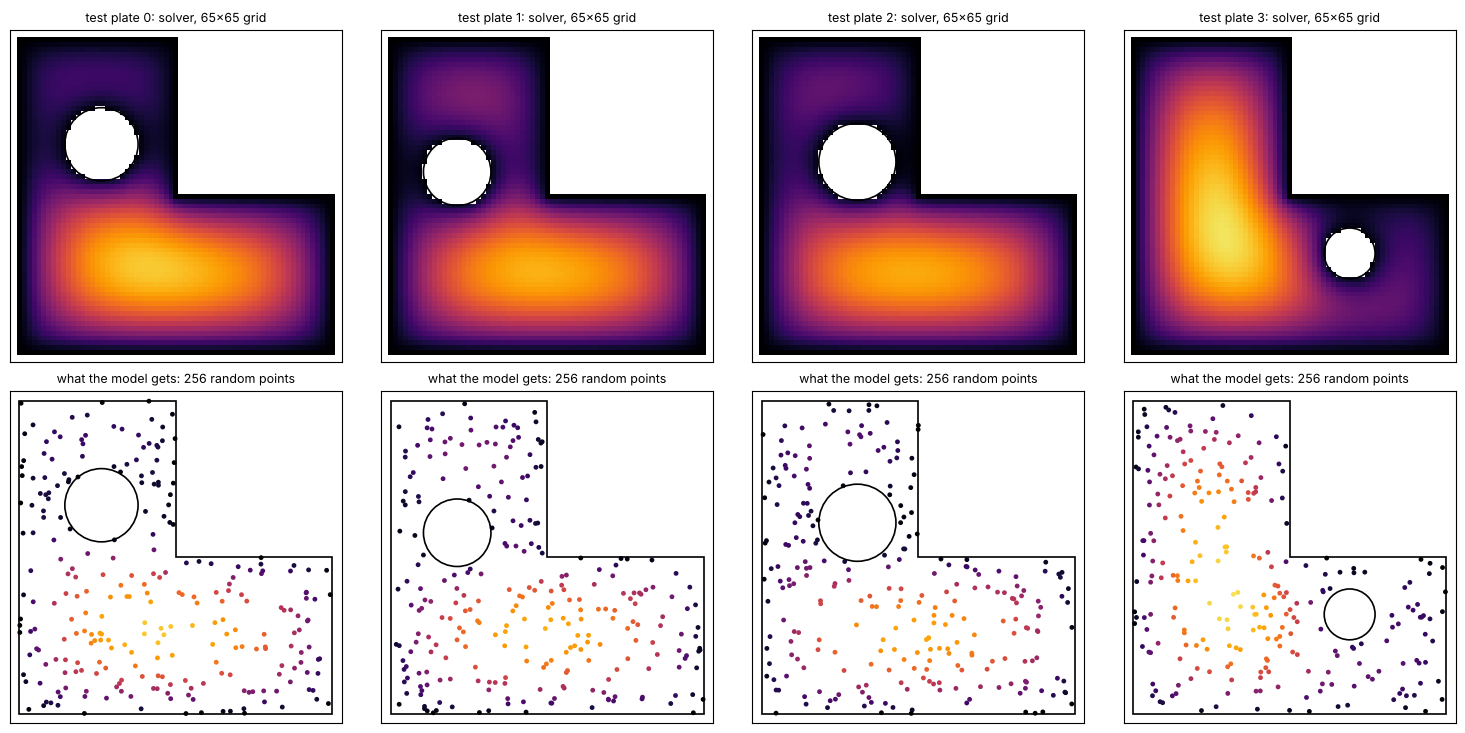

In [2]:
phys = PlateParams()
t0 = time.time()
data = make_dataset(seed=0, n_samples=1200, n_points=256, params=phys)
print(f"solved 1200 plates on a {phys.n_grid}×{phys.n_grid} grid in {time.time() - t0:.1f} s")

train_set = {k: v[:1000] for k, v in data.items()}
test_set = {k: v[1000:] for k, v in data.items()}
F_train, u_train = train_set["features"], train_set["u"]
F_test, u_test = test_set["features"], test_set["u"]
print("train:", F_train.shape, "->", u_train.shape, "   test:", F_test.shape, "->", u_test.shape)

vmax = float(data["u_grid"].max())
fig, axes = plt.subplots(2, 4, figsize=(15, 7.4))
for col, i in enumerate([0, 1, 2, 3]):
    viz.grid_field(axes[0, col], test_set["u_grid"][i], test_set["hole"][i], f"test plate {i}: solver, 65×65 grid", vmax)
    viz.field(axes[1, col], test_set["points"][i], u_test[i], test_set["hole"][i],
              f"what the model gets: 256 random points", vmin=0, vmax=vmax)
plt.tight_layout(); plt.show()

Top row: the solver's temperature. The plate is hottest far from every cold edge, so the hot spot sits in whichever
arm of the L the hole leaves free, and the field is pushed down to zero around the hole. Bottom row: what the model
gets for each plate, 256 points scattered over the plate with the temperature at each point as the target.

### Why not just use the FNO here?

The FNO's global step is an FFT, and an FFT needs values on a **uniform grid over a rectangle (or a torus)**. Here
there is no such grid:

* the domain is an L with a hole, so a bounding box has big regions where the field is not defined;
* the points are scattered, and every plate has its own points;
* the geometry itself is the input that changes.

There are workarounds (fill the box and add a mask, interpolate onto a grid, or deform the domain into a box as
Geo-FNO does), but each adds a step that is not part of the physics. Transolver needs none of them: its input is
just a list of points with features, and every operation is either **per point** or a **weighted sum over points**.

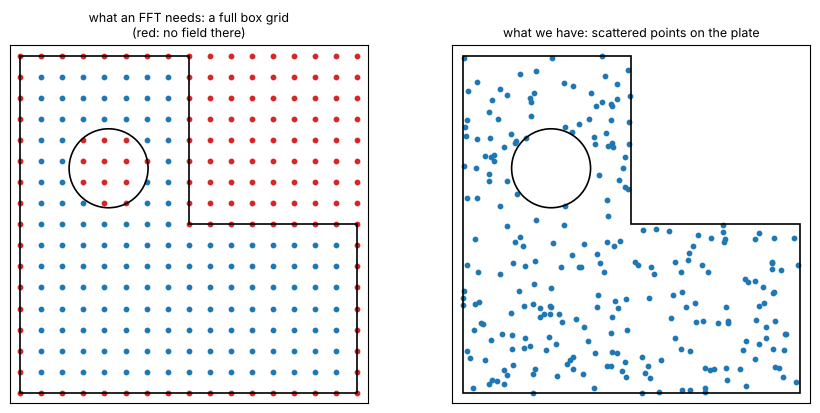

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
i = 0
X, Y = grid_xy(PlateParams(n_grid=17))
inside = free_mask(test_set["hole"][i], PlateParams(n_grid=17))
axes[0].scatter(X[inside], Y[inside], s=10, color="tab:blue"); axes[0].scatter(X[~inside], Y[~inside], s=10, color="tab:red")
viz.plate(axes[0], test_set["hole"][i]); axes[0].set_title("what an FFT needs: a full box grid\n(red: no field there)", fontsize=9)
axes[1].scatter(*test_set["points"][i].T, s=10)
viz.plate(axes[1], test_set["hole"][i]); axes[1].set_title("what we have: scattered points on the plate", fontsize=9)
plt.tight_layout(); plt.show()

## 2. What goes in, what comes out

For one plate Transolver receives an **$N \times 3$ input matrix**:

* **rows = points.** Row $i$ is one point $p_i$ of the cloud, in no particular order.
* **columns = features of that point**: its coordinates $x_i, y_i$ and its distance to the hole's edge,
  $d_i = |p_i - c| - r$. The distance is how the geometry enters, the same way the paper feeds signed distances and
  normals for Shape-Net Car. (Section 8d trains without it.)

The output is **one number per row**: the predicted temperature $u(p_i)$, an $N$-vector. A batch stacks plates:
$(B, N, 3) \to (B, N)$. The same weights run on every plate and on **any $N$**.

For the step-by-step walkthrough we use a small cloud of **$N = 32$ points** on test plate 0, so every matrix fits on
screen.

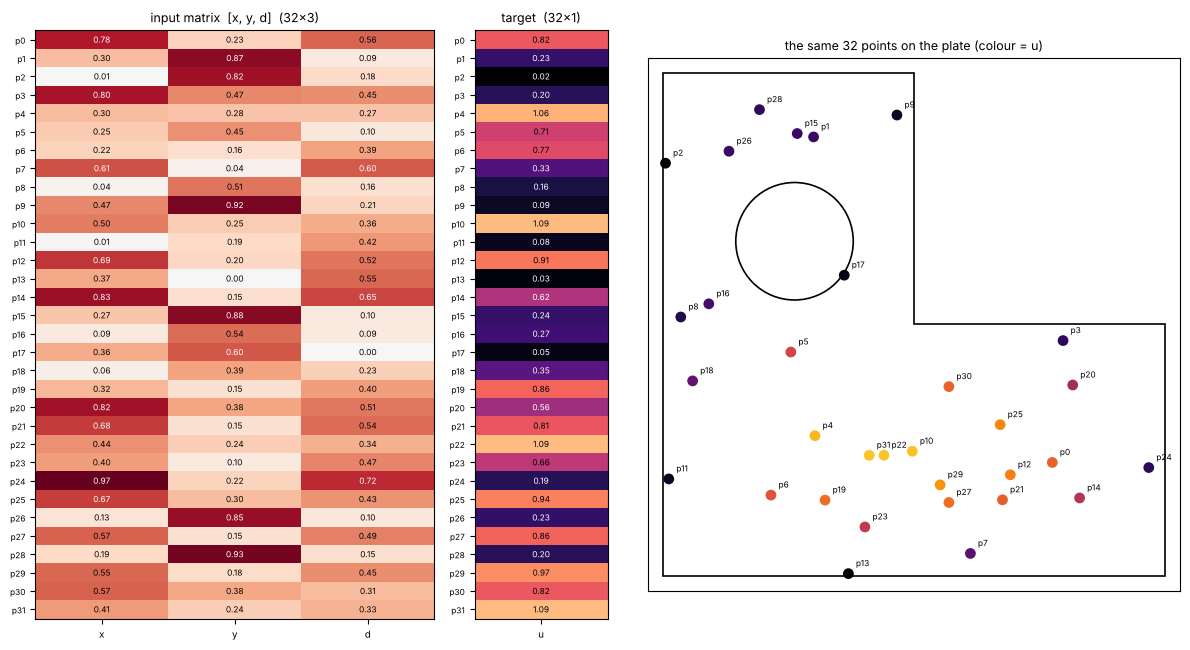

hole: centre (0.262, 0.666), radius 0.117


In [4]:
N = 32
rng = np.random.default_rng(7)
pts32, u32 = sample_cloud(rng, test_set["u_grid"][0], test_set["hole"][0], N, phys)
F32 = make_features(pts32, test_set["hole"][0]).astype(np.float32)
hole0 = test_set["hole"][0]

fig, axes = plt.subplots(1, 3, figsize=(12, 6.6), gridspec_kw=dict(width_ratios=[3, 1, 4]))
viz.matrix(axes[0], F32, viz.point_labels(N), ["x", "y", "d"], "input matrix  [x, y, d]  (32×3)")
viz.matrix(axes[1], u32[:, None], viz.point_labels(N), ["u"], "target  (32×1)", cmap="magma", vmax=vmax)
viz.field(axes[2], pts32, u32, hole0, "the same 32 points on the plate (colour = u)", vmin=0, vmax=vmax, s=60)
for j, (px, py) in enumerate(pts32):
    axes[2].text(px + 0.015, py + 0.015, f"p{j}", fontsize=6)
plt.tight_layout(); plt.show()
print(f"hole: centre ({hole0[0]:.3f}, {hole0[1]:.3f}), radius {hole0[2]:.3f}")

## 3. The architecture, with every shape

Paper Sec. 3 and Fig. 3. Every step is either **pointwise** (the same small matrix applied to every row) or a
**weighted sum over rows** (slice and deslice). Only the second kind moves information between points.

| stage | formula | shape for one plate ($N$ points) |
|---|---|---|
| input | $[x_i, y_i, d_i]$ | $N \times 3$ |
| **embed** (pointwise MLP) | $x_i = \mathrm{GELU}(a_i W_1 + b_1)\, W_2 + b_2$ | $N \times 16$ |
| *Transolver block* ×3 | | |
| LayerNorm | each row to mean 0, variance 1 | $N \times 16$ |
| split into 2 heads | channels 0–7 → head 1, 8–15 → head 2 | $2 \times N \times 8$ |
| point features | $f_i = x_i W_{fx}$, $\;g_i = x_i W_x$ | $2 \times N \times 8$ each |
| **1. slice weights** | $w_{i,:} = \mathrm{softmax}(g_i W_s / \tau_h)$, each row sums to 1 | $2 \times N \times 8$ |
| **2. slice tokens** | $z_m = \sum_i w_{im} f_i \,/\, \sum_i w_{im}$ | $2 \times 8 \times 8$ |
| **3. attention among slices** | $z' = \mathrm{softmax}(q k^\top/\sqrt{8})\, v$ | $2 \times 8 \times 8$ (scores $2\times 8 \times 8$) |
| **4. deslice** | $f'_i = \sum_m w_{im} z'_m$ | $2 \times N \times 8$ |
| merge heads | concatenate, then $W_o$ | $N \times 16$ |
| residual + MLP | $x \mathrel{+}= \mathrm{MLP}(\mathrm{LN}(x))$, $16 \to 32 \to 16$ | $N \times 16$ |
| **decode** (pointwise) | $u_i = \mathrm{LN}(x_i)\, W_{out} + b_{out}$ | $N \times 1$ |

Notation: $N$ points, $C = 16$ channels, $H = 2$ heads of $d = 8$ channels, $M = 8$ slices per head, $L = 3$
blocks. The paper uses $C = 128$ to $256$, $H = 8$, $M = 32$ to $64$, $L = 8$.

**No size in this table depends on $N$ except the number of rows.** The attention matrix is $M \times M$ whatever
$N$ is. That is the whole point of the slices.

In [5]:
cfg = TransolverConfig(in_dim=3, width=16, heads=2, slices=8, layers=3)
params0 = init_params(jax.random.PRNGKey(1), cfg)
trace = jax.jit(partial(apply_with_trace, cfg=cfg))

n_params = sum(int(np.prod(p.shape)) for p in jax.tree_util.tree_leaves(params0))
b = params0["blocks"][0]
per_block = sum(int(np.prod(p.shape)) for p in jax.tree_util.tree_leaves(b))
print(f"parameters: {n_params}   (embed {3*32+32+32*16+16}, each block {per_block}, decoder {16+16+16+1})")
print("one block:")
for k, v in b.items():
    shapes = [tuple(x.shape) for x in jax.tree_util.tree_leaves(v)]
    print(f"   {k:8s} {shapes}")

tr = trace(params0, F32)
print("\ntrace of block 1 for the 32-point cloud:")
for k, v in tr.blocks[0].items():
    print(f"   {k:8s} {str(tuple(v.shape)):12s}")

parameters: 7359   (embed 656, each block 2218, decoder 49)
one block:
   ln1      [(16,), (16,)]
   W_fx     [(16, 16), (16,)]
   W_x      [(16, 16), (16,)]
   W_s      [(8, 8), (8,)]
   log_tau  [(2,)]
   W_q      [(8, 8)]
   W_k      [(8, 8)]
   W_v      [(8, 8)]
   W_o      [(16, 16), (16,)]
   ln2      [(16,), (16,)]
   mlp      [(16, 32), (32,), (32, 16), (16,)]



trace of block 1 for the 32-point cloud:
   attn     (2, 8, 8)   
   f        (2, 32, 8)  
   f_out    (2, 32, 8)  
   g        (2, 32, 8)  
   k        (2, 8, 8)   
   ln1      (32, 16)    
   logits   (2, 32, 8)  
   mass     (2, 8)      
   mlp_out  (32, 16)    
   out      (32, 16)    
   q        (2, 8, 8)   
   tau      (2,)        
   v        (2, 8, 8)   
   w        (2, 32, 8)  
   x_in     (32, 16)    
   x_mid    (32, 16)    
   x_out    (32, 16)    
   z        (2, 8, 8)   
   z_out    (2, 8, 8)   


### The same architecture as a picture

Top: the whole model. Bottom: one Transolver block opened up, for one head. Each box is a tensor; its **height is
the number of rows**, so the $ points are tall boxes and the $ slice tokens are short ones. Read it left to
right and you see the squeeze **N → M → N**: the points are summarised into a few slice tokens, the tokens talk to
each other, and the result is spread back to the points with the same weights $.

Arrow colours say what kind of step it is: **blue** = the same small matrix applied to every row (no point sees
another), **orange** = a weighted sum over all points (slice and deslice), **green** = attention among the $
tokens. Only orange and green move information between points.

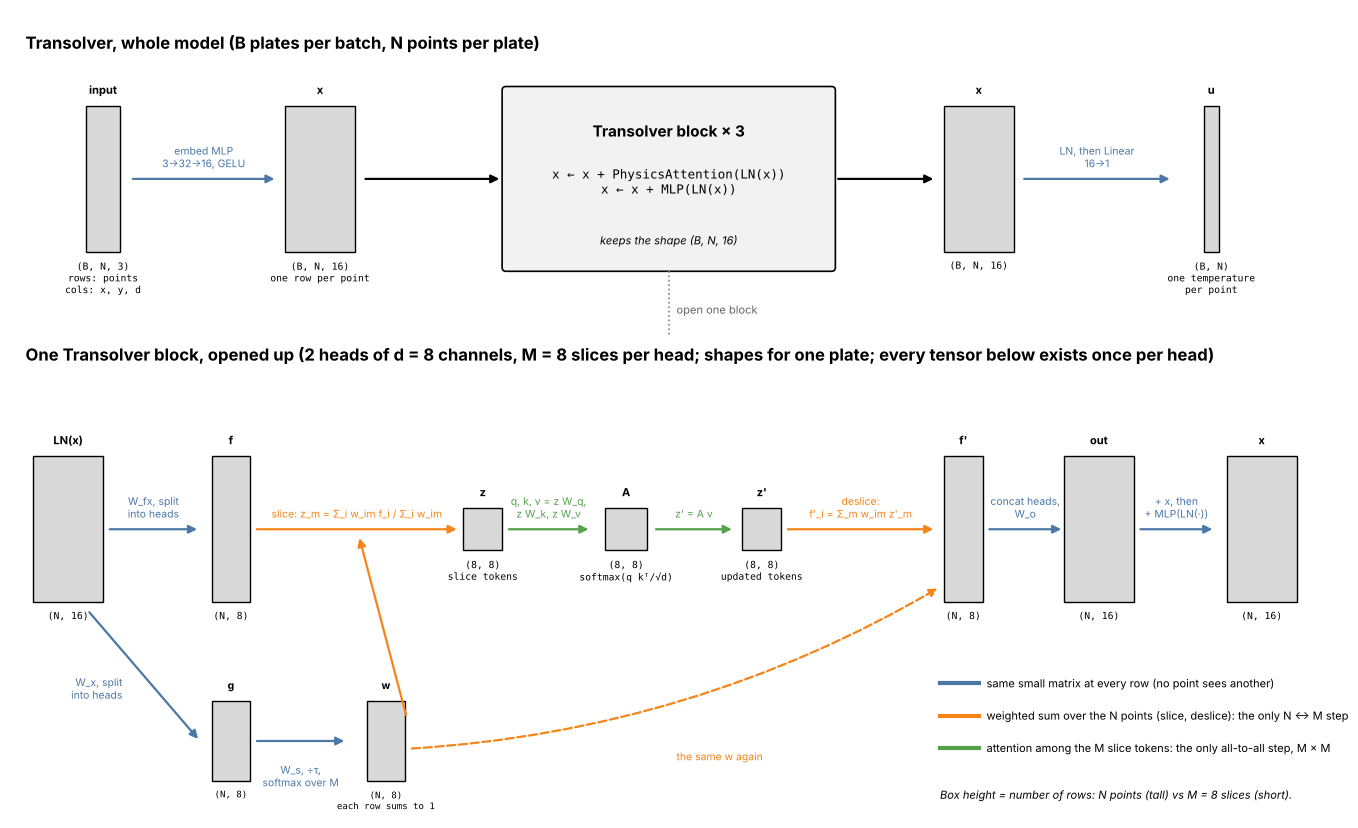

In [ ]:
viz.architecture_diagram(cfg)
plt.show()

## 4. One forward pass, tensor by tensor

We push the 32-point cloud of test plate 0 through the **untrained** network `params0`. The numbers are random
for now; the shapes, the flow and the arithmetic are the point. Section 7 shows the trained values, and section 8b
shows what the trained slices mean.

### 4a. Embed: from 3 numbers per point to 16 channels

A two-layer MLP $3 \to 32 \to 16$ (GELU in between) is applied to **every row separately**. Row $i$ of the
result depends only on row $i$ of the input: no information moves between points yet. Same as the FNO's lift $P$
and the GNS's node encoder.

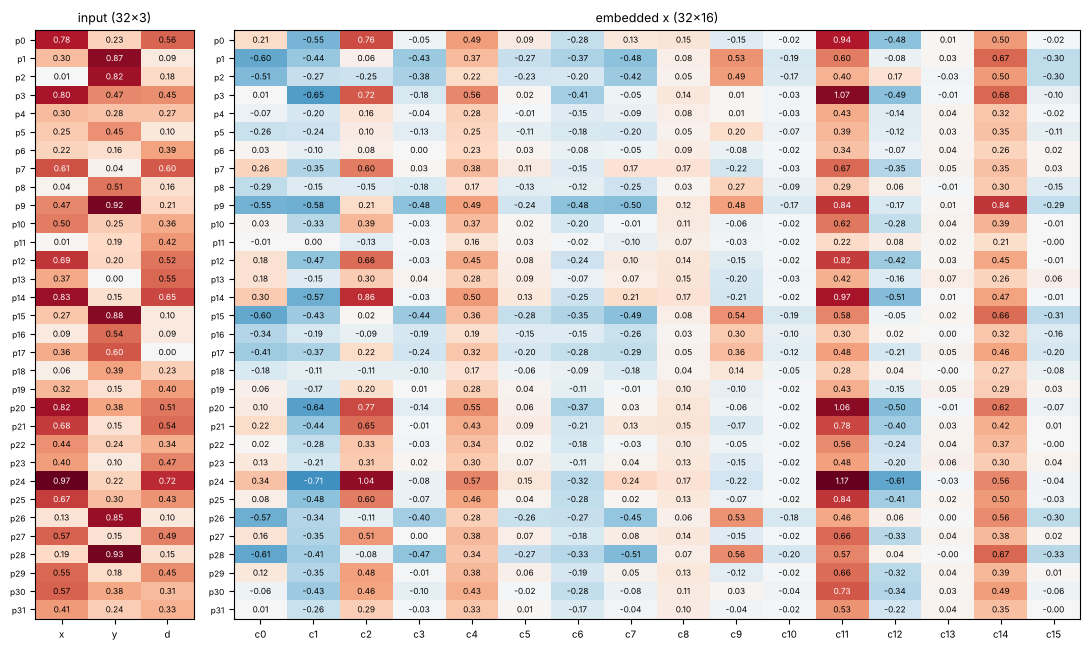

p5: (x, y, d) = [0.2549 0.4451 0.1038]
hidden = GELU((x, y, d) W1 + b1): 32 numbers, first 4 = [ 0.313 -0.075  0.09   0.075]
embedded p5 by hand  = [-0.257 -0.24   0.1   -0.134  0.254 -0.112] ...
embedded p5 by model = [-0.257 -0.24   0.1   -0.134  0.254 -0.112] ...


In [6]:
(W1, b1), (W2, b2) = (tuple(np.asarray(t) for t in layer) for layer in params0["embed"])
fig, axes = plt.subplots(1, 2, figsize=(11, 6.6), gridspec_kw=dict(width_ratios=[3, 16]))
viz.matrix(axes[0], F32, viz.point_labels(N), ["x", "y", "d"], "input (32×3)")
viz.matrix(axes[1], tr.embedded, viz.point_labels(N), viz.channel_labels(16), "embedded x (32×16)")
plt.tight_layout(); plt.show()

i = 5   # worked example: point p5
hidden = np.asarray(jax.nn.gelu(F32[i] @ W1 + b1))
by_hand = hidden @ W2 + b2
print(f"p{i}: (x, y, d) = {F32[i].round(4)}")
print(f"hidden = GELU((x, y, d) W1 + b1): 32 numbers, first 4 = {hidden[:4].round(3)}")
print(f"embedded p{i} by hand  = {by_hand[:6].round(3)} ...")
print(f"embedded p{i} by model = {np.asarray(tr.embedded[i, :6]).round(3)} ...")

#### Aside: what one hidden layer does, as lines on the plate

The embedding is a small MLP: a linear map, then GELU (a smooth ReLU), then another linear map. To build intuition
for what those layers compute, here is a hand-built network with **only $(x, y)$ as inputs** (no $d$) and ReLU.

* **One neuron = one straight line, and one question.** $h = \mathrm{ReLU}(w_x x + w_y y + b)$ is zero on one side
  of the line $w_x x + w_y y + b = 0$ and grows linearly on the other. So it answers "which side of this line am I,
  and how far?" Top row: five such neurons, with lines tangent to a pentagon around the hole.
* **Width = more questions about the same input.** Summing the five answers (weights $-1$, plus a bias, then ReLU)
  gives $A$ = "inside all five lines", a pentagon that approximates "close to the hole". More neurons would give a
  rounder polygon.
* **Depth = follow-up questions.** A second-layer neuron takes the layer-1 answers as *its* inputs. With
  $B$ = "near the bottom edge" (one more line), the layer-2 neuron $\mathrm{ReLU}(A + B - 1)$ is on only where
  both answers are yes: "close to the hole **and** near the edge".

A trained network finds its own lines (and GELU makes the corners soft), and its neurons are rarely this tidy. The
picture also shows why the distance feature $d$ helps so much (section 8d): with $d$ as an input, "close to the
hole?" is a single neuron, $\mathrm{ReLU}(0.05 - d)$, instead of five lines and a sum.

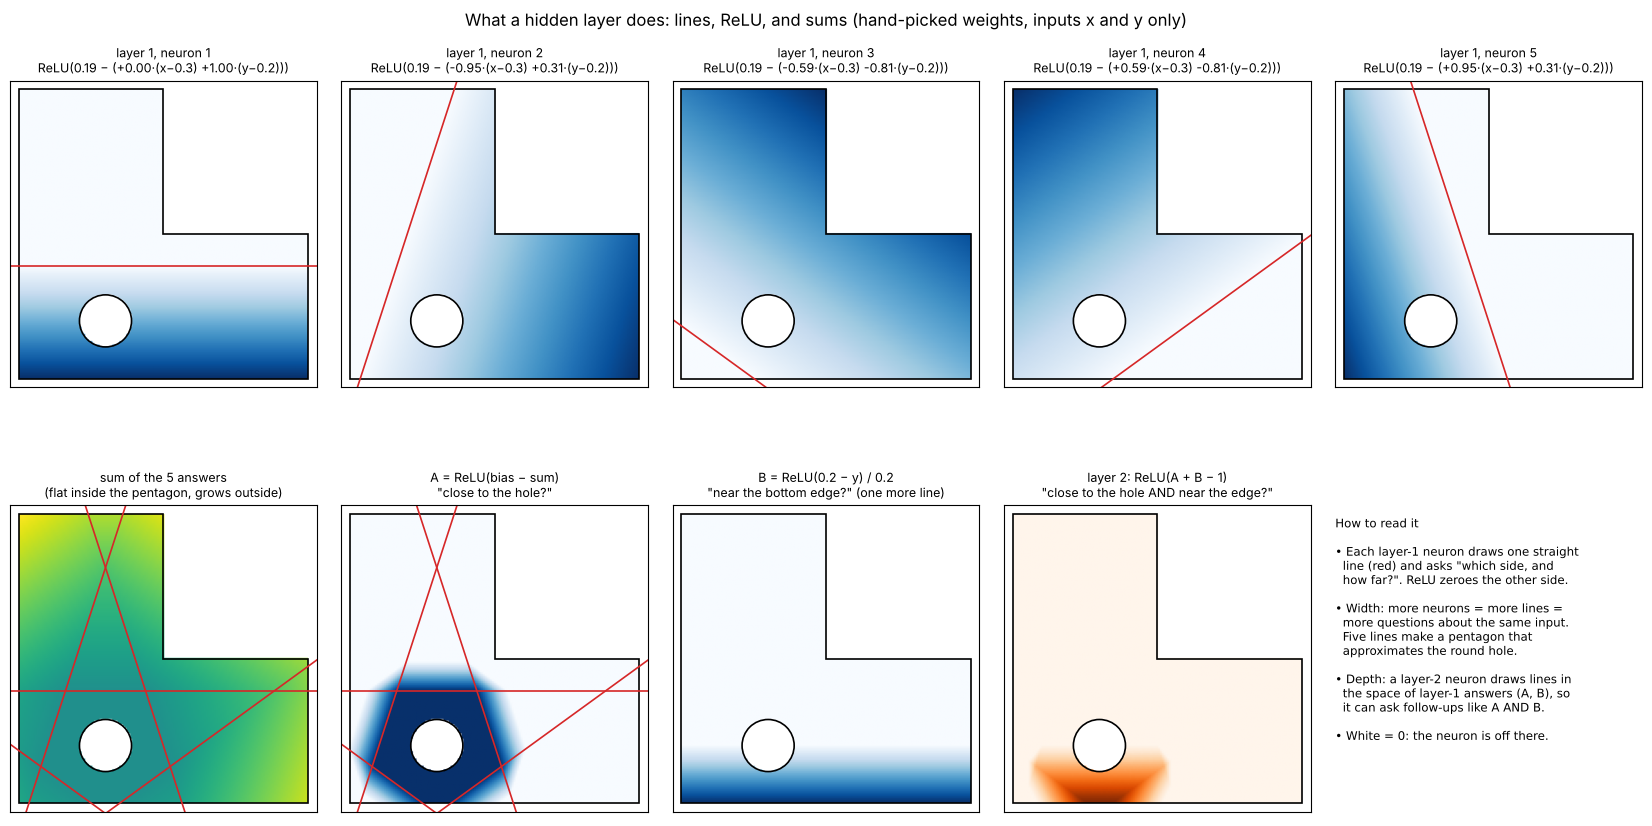

In [ ]:
viz.hidden_layer_intuition(hole=(0.3, 0.2, 0.09))
plt.show()

### 4b. LayerNorm: make every row comparable

Before attention, each row is normalised over its 16 channels: subtract the row mean, divide by the row standard
deviation, then scale by $\gamma$ and shift by $\beta$ (learned, 16 numbers each; at initialisation $\gamma = 1$,
$\beta = 0$). It acts on one point at a time.

In [7]:
B1 = tr.blocks[0]
row = np.asarray(tr.embedded[i])
by_hand = (row - row.mean()) / np.sqrt(row.var() + 1e-5)
print(f"p{i}: mean {row.mean():.4f}, std {row.std():.4f}")
print(f"LN(p{i}) by hand  = {by_hand[:6].round(3)} ...")
print(f"LN(p{i}) by model = {np.asarray(B1['ln1'][i, :6]).round(3)} ...")

p5: mean -0.0032, std 0.2018
LN(p5) by hand  = [-1.255 -1.172  0.513 -0.646  1.277 -0.537] ...
LN(p5) by model = [-1.255 -1.172  0.513 -0.646  1.277 -0.537] ...


### 4c. Two projections per point, split into heads

From the normalised $x_i$ (16 numbers) each block computes two pointwise projections:

* $f_i = x_i W_{fx} + b$: **what point $i$ contributes** to a slice token (like the "value" in attention);
* $g_i = x_i W_x + b$: **what point $i$ uses to decide which slice it belongs to**.

Both are $N \times 16$ and are split into $H = 2$ heads of 8 channels: channels 0–7 go to head 1, 8–15 to head 2.
Each head has its own slices, so the model can group the points in two different ways at once. From here on we
follow **head 1**.

### 4d. Step 1 of Physics-Attention: slice weights

Each point gets a probability for each of the $M = 8$ slices:

$$
w_{i,:} = \mathrm{softmax}\!\left(\frac{g_i W_s + b_s}{\tau_h}\right), \qquad \sum_{m} w_{im} = 1 .
$$

* **rows of $w$ = points, columns = slices.** Row $i$ says how much point $i$ belongs to each slice. It is a *soft*
  assignment: a point can be partly in several slices.
* $W_s$ is an $8 \times 8$ matrix shared by all points (and by both heads), so two points with similar features get
  similar rows, **wherever they are in the domain**. That is what *allows* a slice to be a "physical state" rather than a region. (Whether the trained slices
  really are states is the question of section 8b.)
* $\tau_h$ is a learned temperature per head (starts at 0.5). A small $\tau$ makes the softmax sharper, so each point
  commits to fewer slices.
* The **column sums** $\sum_i w_{im}$ are the "mass" of each slice: roughly how many points it holds.

Worked example: point p5, head 1.

In [8]:
h = 0
g5 = np.asarray(B1["g"][h, i])
Ws, bs = (np.asarray(t) for t in params0["blocks"][0]["W_s"])
tau = float(B1["tau"][h])
logits = g5 @ Ws + bs
e = np.exp(logits / tau - (logits / tau).max())
print(f"g_p{i} (head 1, 8 numbers)  = {g5.round(3)}")
print(f"logits g W_s + b_s          = {logits.round(3)}")
print(f"tau = {tau:.3f};   logits / tau = {(logits / tau).round(3)}")
print(f"softmax by hand             = {(e / e.sum()).round(3)}   (sum {(e / e.sum()).sum():.3f})")
print(f"w[p{i}] from the model        = {np.asarray(B1['w'][h, i]).round(3)}")
print(f"\nslice masses (column sums of w, head 1) = {np.asarray(B1['mass'][h]).round(2)}   total = {float(B1['mass'][h].sum()):.1f} = N")

g_p5 (head 1, 8 numbers)  = [ 0.926  0.9    1.176  0.265  0.206  0.264 -1.262  0.857]
logits g W_s + b_s          = [ 1.724  0.728 -0.653 -0.454  0.265  0.513 -0.287  1.005]
tau = 0.500;   logits / tau = [ 3.448  1.456 -1.306 -0.909  0.529  1.025 -0.574  2.01 ]
softmax by hand             = [0.643 0.088 0.006 0.008 0.035 0.057 0.012 0.153]   (sum 1.000)
w[p5] from the model        = [0.643 0.088 0.006 0.008 0.035 0.057 0.012 0.153]



slice masses (column sums of w, head 1) = [10.42  2.51  0.23  0.98  1.3   1.78  0.91 13.86]   total = 32.0 = N


### 4e. Step 2: slice tokens, one weighted average per slice

Each slice becomes **one token**: the weighted average of the point features $f_i$, with the slice's column of $w$
as the weights:

$$
z_m = \frac{\sum_{i=1}^{N} w_{im}\, f_i}{\sum_{i=1}^{N} w_{im}} .
$$

* **rows of $z$ = slices, columns = the 8 feature channels of the head.** Whatever $N$ is, $z$ is $8 \times 8$.
* This is where the $N$ points are compressed into $M$ tokens. Because it is an average (not a sum), a cloud with
  more points gives about the same token, only a less noisy estimate. In the continuum limit it is an integral over
  the domain, $z_m \approx \int_\Omega w_m(p) f(p)\,dp \,/ \int_\Omega w_m(p)\,dp$ (paper Theorem 3.1).

Worked example: token $z_0$, channel 0.

In [9]:
f0 = np.asarray(B1["f"][h])            # (32, 8) point features of head 1
w0 = np.asarray(B1["w"][h])            # (32, 8) slice weights of head 1
m = 0
num = (w0[:, m] * f0[:, 0]).sum()
den = w0[:, m].sum()
print("first 4 terms w_i0 · f_i,c0:", (w0[:4, m] * f0[:4, 0]).round(4))
print(f"z_0, channel 0 by hand = {num:.4f} / {den:.4f} = {num / den:.4f}")
print(f"z_0, channel 0 model   = {float(B1['z'][h, m, 0]):.4f}")

first 4 terms w_i0 · f_i,c0: [ 0.0061 -0.7353 -0.5733 -0.0691]
z_0, channel 0 by hand = -9.7779 / 10.4186 = -0.9385


z_0, channel 0 model   = -0.9385


### 4f. Step 3: ordinary attention, but among the 8 slice tokens

Now the tokens talk to each other, with the attention of Vaswani et al. 2017:

$$
q = z W_q,\quad k = z W_k,\quad v = z W_v, \qquad
A = \mathrm{softmax}\!\left(\frac{q k^\top}{\sqrt d}\right), \qquad z' = A\, v .
$$

* **rows of $A$ = the slice that is updated, columns = the slice it reads from**; each row sums to 1.
* $A$ is $8 \times 8 = 64$ numbers. Plain attention between the 32 points would be $32 \times 32 = 1024$, and on a
  real mesh with $N = 10^6$ points it would be $10^{12}$. Here it stays $M^2$ for any mesh.
* This is the **only** place where far-apart points exchange information directly: a point near the hole and a
  point in the far arm of the L talk through their slices.

Worked example: row $s_0$ of $A$ and one entry of $z'$.

In [10]:
q, k, v = (np.asarray(B1[n][h]) for n in ("q", "k", "v"))
scores = q[0] @ k.T / np.sqrt(q.shape[1])
a0 = np.exp(scores - scores.max()); a0 /= a0.sum()
print(f"scores q_0 · k_m / sqrt(8)  = {scores.round(3)}")
print(f"softmax (row s0 of A) hand  = {a0.round(3)}")
print(f"row s0 of A from the model  = {np.asarray(B1['attn'][h, 0]).round(3)}")
print(f"z'_0, channel 0 = sum_m A_0m v_m,0 = {(a0 * v[:, 0]).sum():.4f}   (model {float(B1['z_out'][h, 0, 0]):.4f})")

scores q_0 · k_m / sqrt(8)  = [-0.097 -0.117 -0.042 -0.091 -0.088 -0.093 -0.078 -0.054]
softmax (row s0 of A) hand  = [0.123 0.121 0.13  0.124 0.124 0.124 0.126 0.129]


row s0 of A from the model  = [0.123 0.121 0.13  0.124 0.124 0.124 0.126 0.129]
z'_0, channel 0 = sum_m A_0m v_m,0 = 1.2378   (model 1.2378)


### 4g. Step 4: deslice, back to the points

Every point gets back a mix of the updated tokens, **with the same weights it used to build them**:

$$
f'_i = \sum_{m=1}^{M} w_{im}\, z'_m .
$$

* **rows of $f'$ = points again, columns = the head's 8 channels.** We are back to $N$ rows.
* Two points with the same slice weights get the same $f'$, however far apart they are.

Then the two heads are concatenated ($N \times 16$), multiplied by $W_o$, and **added** to the block input
(residual connection). Worked example: point p5, channel 0.

In [11]:
z_out = np.asarray(B1["z_out"][h])
by_hand = (w0[i] * z_out[:, 0]).sum()
print(f"w[p{i}]           = {w0[i].round(3)}")
print(f"z'[:, channel 0] = {z_out[:, 0].round(3)}")
print(f"f'[p{i}, c0] by hand = sum_m w_im z'_m0 = {by_hand:.4f}   (model {float(B1['f_out'][h, i, 0]):.4f})")

Wo, bo = (np.asarray(t) for t in params0["blocks"][0]["W_o"])
merged = np.concatenate([np.asarray(B1["f_out"][0, i]), np.asarray(B1["f_out"][1, i])])
print(f"\nattention output for p{i} = [f'_head1, f'_head2] W_o + b_o: by hand {(merged @ Wo + bo)[:4].round(3)} ...")
print(f"                                                    model   {np.asarray(B1['out'][i, :4]).round(3)} ...")
print(f"x after the residual = x_in + out: {np.asarray(B1['x_in'][i, :4] + B1['out'][i, :4]).round(3)} ... (model {np.asarray(B1['x_mid'][i, :4]).round(3)} ...)")

w[p5]           = [0.643 0.088 0.006 0.008 0.035 0.057 0.012 0.153]
z'[:, channel 0] = [1.238 1.258 1.209 1.215 1.225 1.254 1.213 1.204]


f'[p5, c0] by hand = sum_m w_im z'_m0 = 1.2343   (model 1.2343)

attention output for p5 = [f'_head1, f'_head2] W_o + b_o: by hand [0.341 0.253 0.906 0.478] ...


                                                    model   [0.341 0.253 0.906 0.478] ...
x after the residual = x_in + out: [0.085 0.013 1.006 0.345] ... (model [0.085 0.013 1.006 0.345] ...)


### 4h. The whole Physics-Attention head in one picture

Left to right: the point features $f$ ($N \times d$) and the slice weights $w$ ($N \times M$) go in, the slice
tokens $z$ ($M \times d$) are their weighted averages, the attention matrix ($M \times M$) mixes the tokens into
$z'$, and deslicing gives $f'$ ($N \times d$) back on the points. Far right: each point coloured by its most likely
slice (faint = unsure). With random weights the slices are a meaningless soup; section 8b shows the trained ones.

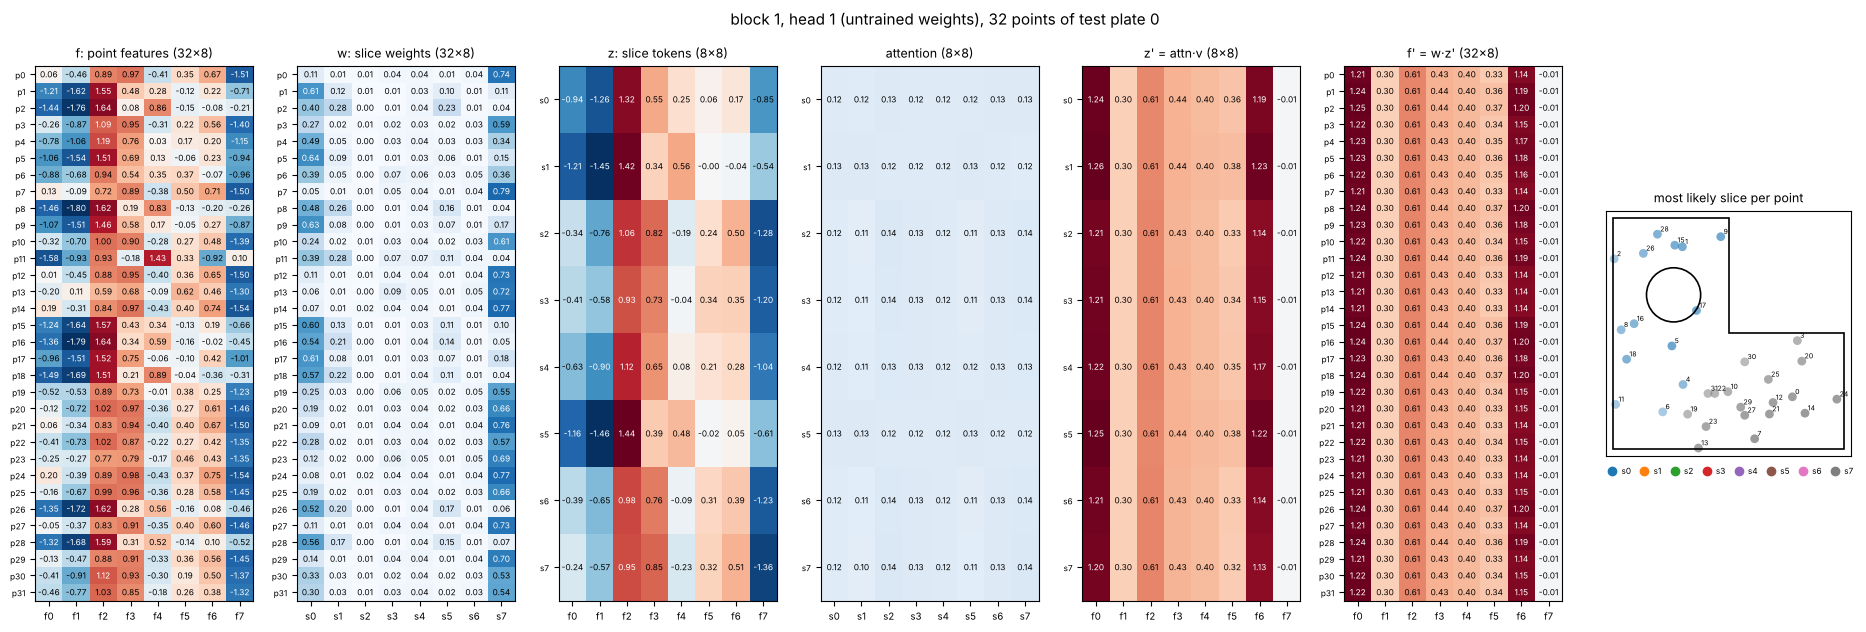

In [12]:
viz.physics_attention_flow(tr.blocks[0], 0, pts32, hole0, "block 1, head 1 (untrained weights), 32 points of test plate 0")
plt.show()

### 4i. The MLP half of the block, and the decoder

After attention, each block applies a pointwise MLP ($16 \to 32 \to 16$, GELU) to the LayerNorm of every row and
adds it back: $x \leftarrow x + \mathrm{MLP}(\mathrm{LN}(x))$. Like the embedding, it never mixes points; it
transforms what each point received from the slices.

After 3 blocks, a final LayerNorm and a $16 \to 1$ linear map give the temperature at each point.

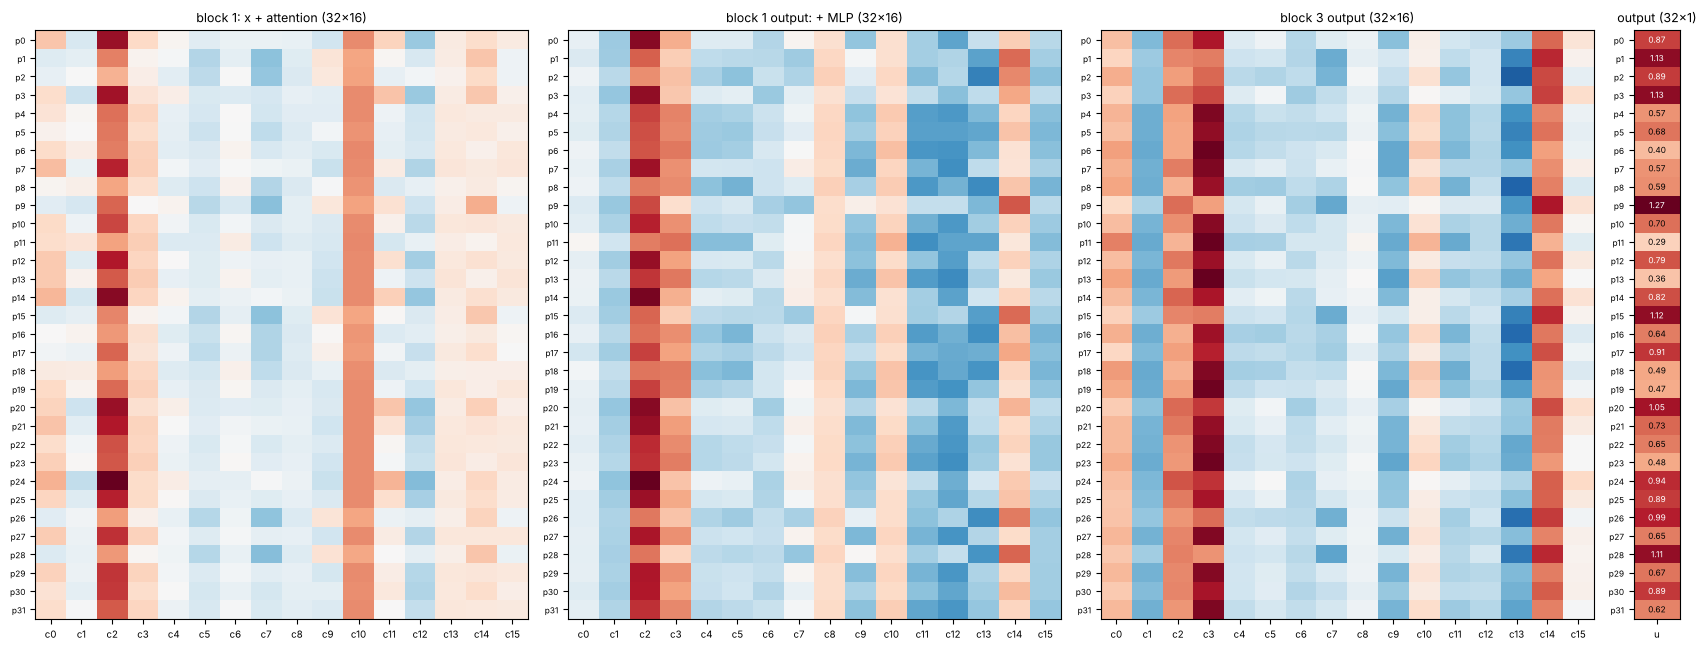

u(p5) by hand = LN(x_p5) · W_out + b_out = 0.6775   (model 0.6775)


In [13]:
fig, axes = plt.subplots(1, 4, figsize=(17, 6.6), gridspec_kw=dict(width_ratios=[16, 16, 16, 1.5]))
viz.matrix(axes[0], tr.blocks[0]["x_mid"], viz.point_labels(N), viz.channel_labels(16), "block 1: x + attention (32×16)", annotate=False)
viz.matrix(axes[1], tr.blocks[0]["x_out"], viz.point_labels(N), viz.channel_labels(16), "block 1 output: + MLP (32×16)", annotate=False)
viz.matrix(axes[2], tr.blocks[-1]["x_out"], viz.point_labels(N), viz.channel_labels(16), "block 3 output (32×16)", annotate=False)
viz.matrix(axes[3], np.asarray(tr.output)[:, None], viz.point_labels(N), ["u"], "output (32×1)")
plt.tight_layout(); plt.show()

Wout, bout = (np.asarray(t) for t in params0["out"])
x_last = np.asarray(tr.blocks[-1]["x_out"][i])
ln = (x_last - x_last.mean()) / np.sqrt(x_last.var() + 1e-5)
print(f"u(p{i}) by hand = LN(x_p{i}) · W_out + b_out = {(ln @ Wout + bout)[0]:.4f}   (model {float(tr.output[i]):.4f})")

### 4j. Two properties that follow from the construction

**The order of the points does not matter.** Every step is per point or a sum over points, so shuffling the rows of
the input shuffles the rows of the output in the same way (*permutation equivariance*). A point cloud has no
natural order, so this is what we want. (An FNO, by contrast, needs the grid order for its FFT.)

**The cost is linear in $N$.** Plain attention over points builds an $N \times N$ matrix. Physics-Attention builds an
$N \times M$ weight matrix and an $M \times M$ attention matrix.

In [14]:
perm = np.random.default_rng(0).permutation(N)
out_perm = np.asarray(apply(params0, F32[perm], cfg))
print("max |model(shuffled rows) - shuffled(model(rows))| =", np.abs(out_perm - np.asarray(tr.output)[perm]).max())

print("\nnumbers in the attention-related matrices per head:")
for n_pts in [32, 256, 2_000, 1_000_000]:
    print(f"   N = {n_pts:>9,}:  plain attention N² = {n_pts**2:>17,}   Physics-Attention N·M + M² = {n_pts*cfg.slices + cfg.slices**2:>10,}")

max |model(shuffled rows) - shuffled(model(rows))| = 7.1525574e-07

numbers in the attention-related matrices per head:
   N =        32:  plain attention N² =             1,024   Physics-Attention N·M + M² =        320
   N =       256:  plain attention N² =            65,536   Physics-Attention N·M + M² =      2,112
   N =     2,000:  plain attention N² =         4,000,000   Physics-Attention N·M + M² =     16,064
   N = 1,000,000:  plain attention N² = 1,000,000,000,000   Physics-Attention N·M + M² =  8,000,064


## 5. The loss, and where the gradient comes from

The paper reports the **relative $L^2$ error** for every benchmark, and we train on it, like the FNO:

$$
\mathcal L(\theta) = \frac1B \sum_{b=1}^{B} \frac{\big\|G_\theta(a_b) - u_b\big\|_2}{\|u_b\|_2} .
$$

Dividing by $\|u_b\|$ makes plates with small and large temperatures count equally, and makes the number roughly
independent of how many points the cloud has (both norms grow like $\sqrt N$). That is what lets us compare 64 and
2000 points in section 8c.

The gradient $\partial \mathcal L / \partial \theta$ is ordinary reverse-mode autodiff through section 4. **There is
no PDE in the loss.** The physics enters only through the solver's data and the geometry feature (section 9 checks
how well the PDE ends up satisfied anyway).

Worked example with the untrained network on the 32-point cloud:

In [15]:
pred = np.asarray(tr.output)
num, den = np.linalg.norm(pred - u32), np.linalg.norm(u32)
print(f"||pred - u|| = {num:.4f},  ||u|| = {den:.4f},  relative L2 = {num / den:.4f}")
print(f"relative_l2 from src.training = {float(relative_l2(pred, u32)):.4f}")
print(f"batch loss on 200 test plates (256 points each) = {evaluate(params0, F_test, u_test, cfg):.4f}")

grads = jax.grad(batch_loss)(params0, F_test[:16], u_test[:16], cfg)
print("\nthe gradient pytree has the shape of the parameters, e.g. dL/dW_s of block 1:", grads["blocks"][0]["W_s"][0].shape)

||pred - u|| = 3.0704,  ||u|| = 3.6945,  relative L2 = 0.8311
relative_l2 from src.training = 0.8311


batch loss on 200 test plates (256 points each) = 1.0174



the gradient pytree has the shape of the parameters, e.g. dL/dW_s of block 1: (8, 8)


Two baselines to beat: predicting 0 everywhere gives 1.0, and predicting the *average* temperature field of the
training plates (ignoring the hole) gives the number below. The model has to learn how the hole reshapes the
field to do better than that.

In [16]:
mean_field = data["u_grid"][:1000].mean(0)
X, Y = grid_xy(phys)
def mean_baseline(points):
    ix, iy = np.rint(points[:, 0] * (phys.n_grid - 1)).astype(int), np.rint(points[:, 1] * (phys.n_grid - 1)).astype(int)
    return mean_field[iy, ix]
base = np.mean([float(relative_l2(mean_baseline(p), u)) for p, u in zip(test_set["points"], u_test)])
print(f"'average plate' baseline, test relative L2 = {base:.3f}")

'average plate' baseline, test relative L2 = 0.349


## 6. Train it (and keep snapshots)

1000 training plates, 256 points each, mini-batches of 16 plates, AdamW with a one-cycle learning-rate schedule (as
in the paper code). A copy of the weights is kept every 100 steps for the explorer.

step   500   relative L2 (train batch) = 0.1216


step  1000   relative L2 (train batch) = 0.0925


step  1500   relative L2 (train batch) = 0.0621


step  2000   relative L2 (train batch) = 0.0345


step  2500   relative L2 (train batch) = 0.0321


step  3000   relative L2 (train batch) = 0.0281
trained in 78 s


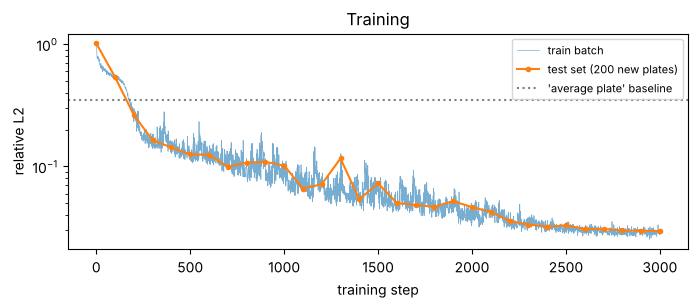

final test relative L2 error: 0.0297


In [17]:
t0 = time.time()
params, snapshots, snap_steps, losses = train(params0, F_train, u_train, cfg, n_steps=3000, batch_size=16,
                                              lr=3e-3, snapshot_every=100, log_every=500)
print(f"trained in {time.time() - t0:.0f} s")

test_err = [evaluate(p, F_test, u_test, cfg) for p in snapshots]
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.semilogy(losses, lw=0.5, alpha=0.6, label="train batch")
ax.semilogy(snap_steps, test_err, "o-", ms=3, label="test set (200 new plates)")
ax.axhline(base, color="0.5", ls=":", label="'average plate' baseline")
ax.set_xlabel("training step"); ax.set_ylabel("relative L2"); ax.legend(fontsize=8); ax.set_title("Training")
plt.show()
print(f"final test relative L2 error: {test_err[-1]:.4f}")

## 7. Interactive explorer: what is inside the network, at any point of training?

Four sliders (press **Run Interact** after moving them):

* **training step**: which weight snapshot to use (0 = random weights, 3000 = trained).
* **test plate**: which of the 200 unseen plates is fed in (256 points each).
* **block** and **head**: which Physics-Attention layer to look at.

Top row: the true temperature, the prediction, the error, and every point coloured by its most likely slice. Bottom
row: the weight $w_{im}$ of each of the 8 slices on the plate (one small map per slice), the slice masses, and the
$8 \times 8$ attention matrix among the slice tokens.

Things to try:

* At step 0 the slices are a random speckle and the prediction is flat. Within a few hundred steps the slices turn
  into **smooth, large patches**, and only a few of the 8 slices keep most of the mass.
* Move the hole (change the test plate) at the final step and watch whether the slices move with it. Section 8b
  measures this.
* Compare the heads: they cut the same plate into different patches.

In [18]:
import ipywidgets as w

traces = {}
def get_trace(k, i):
    if (k, i) not in traces:
        traces[(k, i)] = trace(snapshots[k], F_test[i])
    return traces[(k, i)]

def explore(snapshot, plate, block, head):
    tr_ = get_trace(snapshot, plate)
    B = tr_.blocks[block - 1]
    pts, hole, u = test_set["points"][plate], test_set["hole"][plate], u_test[plate]
    pred = np.asarray(tr_.output)
    wts = np.asarray(B["w"][head - 1])
    fig = plt.figure(figsize=(17, 7.4))
    gs = fig.add_gridspec(2, 8, height_ratios=[2.2, 1])
    err = float(relative_l2(pred, u))
    ax = [fig.add_subplot(gs[0, 2 * c: 2 * c + 2]) for c in range(4)]
    viz.field(ax[0], pts, u, hole, "true u", 0, vmax, colorbar=True)
    viz.field(ax[1], pts, pred, hole, f"prediction (rel. L2 {err:.3f})", 0, vmax, colorbar=True)
    viz.field(ax[2], pts, pred - u, hole, "prediction - true", -0.2, 0.2, cmap="RdBu_r", colorbar=True)
    viz.slice_map(ax[3], pts, wts, hole, f"block {block}, head {head}: most likely slice (τ = {float(B['tau'][head - 1]):.2f})")
    viz.slice_legend(ax[3], cfg.slices)
    inner = gs[1, :6].subgridspec(1, cfg.slices)
    for m in range(cfg.slices):
        a = fig.add_subplot(inner[0, m])
        viz.field(a, pts, wts[:, m], hole, f"w[:, s{m}]  mass {wts[:, m].sum():.0f}", 0, 1, cmap="Blues", s=5)
    a = fig.add_subplot(gs[1, 6:])
    viz.matrix(a, np.asarray(B["attn"][head - 1]), viz.slice_labels(8), viz.slice_labels(8), "attention among slices", vmax=1, cmap="Blues", fontsize=5)
    fig.suptitle(f"training step {snap_steps[snapshot]}, test plate {plate}", fontsize=12)
    plt.tight_layout(); plt.show()

w.interact_manual(explore,
           snapshot=w.IntSlider(value=len(snapshots) - 1, min=0, max=len(snapshots) - 1, description="snapshot"),
           plate=w.IntSlider(value=0, min=0, max=len(u_test) - 1, description="test plate"),
           block=w.IntSlider(value=1, min=1, max=cfg.layers, description="block"),
           head=w.IntSlider(value=1, min=1, max=cfg.heads, description="head"));

interactive(children=(IntSlider(value=30, description='snapshot', max=30), IntSlider(value=0, description='tes…

### Static version: the same plate at three points in training

Some heads end up with sharp slices (each point clearly in one slice), others stay soft. We measure the sharpness
by the mean entropy of a point's slice weights, divided by its maximum $\log M$ (1 = uniform over all slices, 0 =
every point in exactly one slice), and show the sharpest head.

block 1, head 1: entropy / log M  untrained 0.58 -> trained 0.63
block 1, head 2: entropy / log M  untrained 0.67 -> trained 0.22
block 2, head 1: entropy / log M  untrained 0.65 -> trained 0.43
block 2, head 2: entropy / log M  untrained 0.35 -> trained 0.50
block 3, head 1: entropy / log M  untrained 0.60 -> trained 0.57
block 3, head 2: entropy / log M  untrained 0.81 -> trained 0.39

sharpest: block 1, head 2


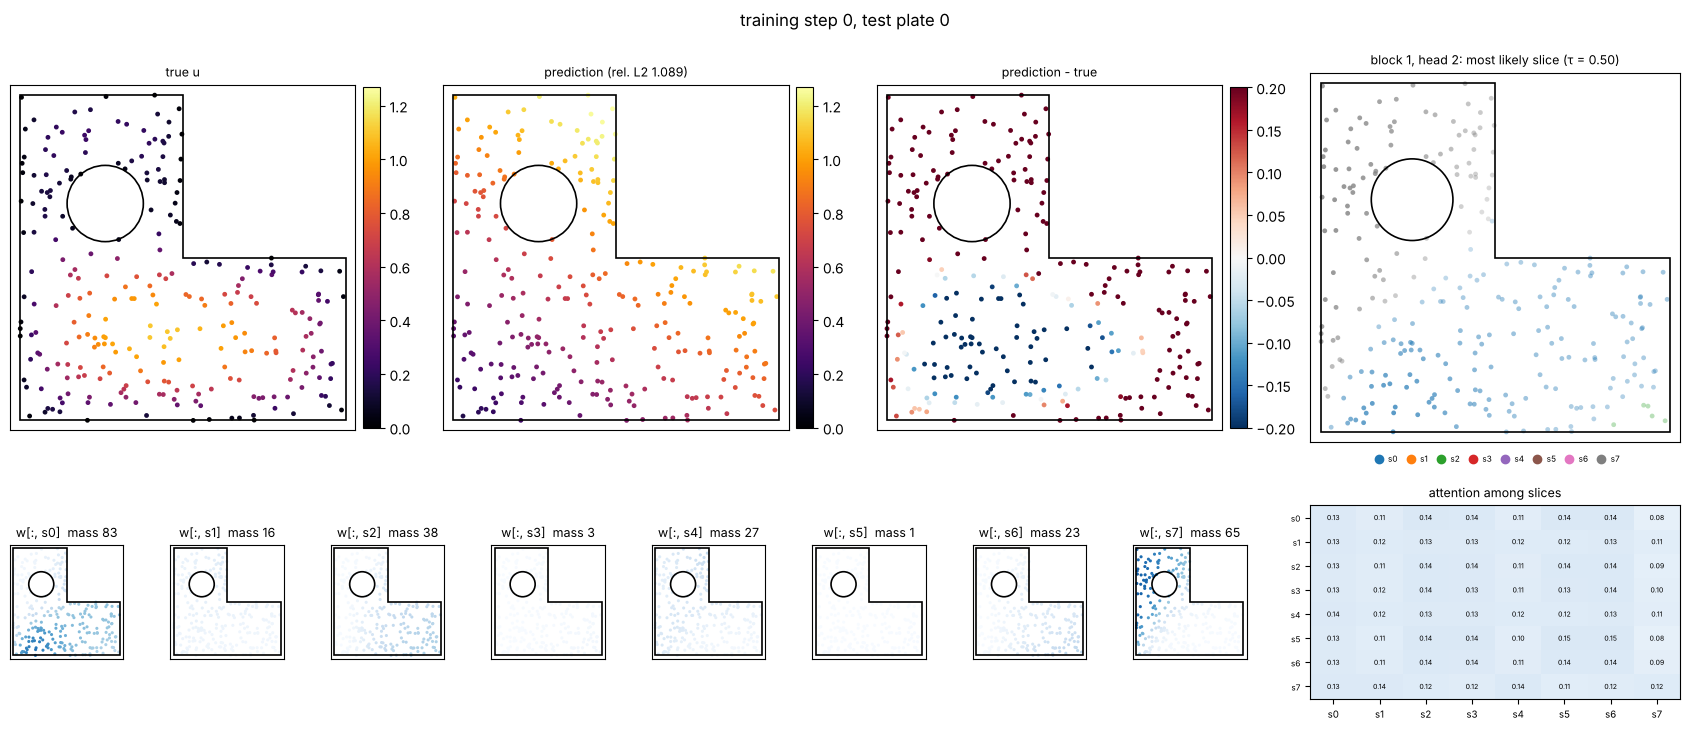

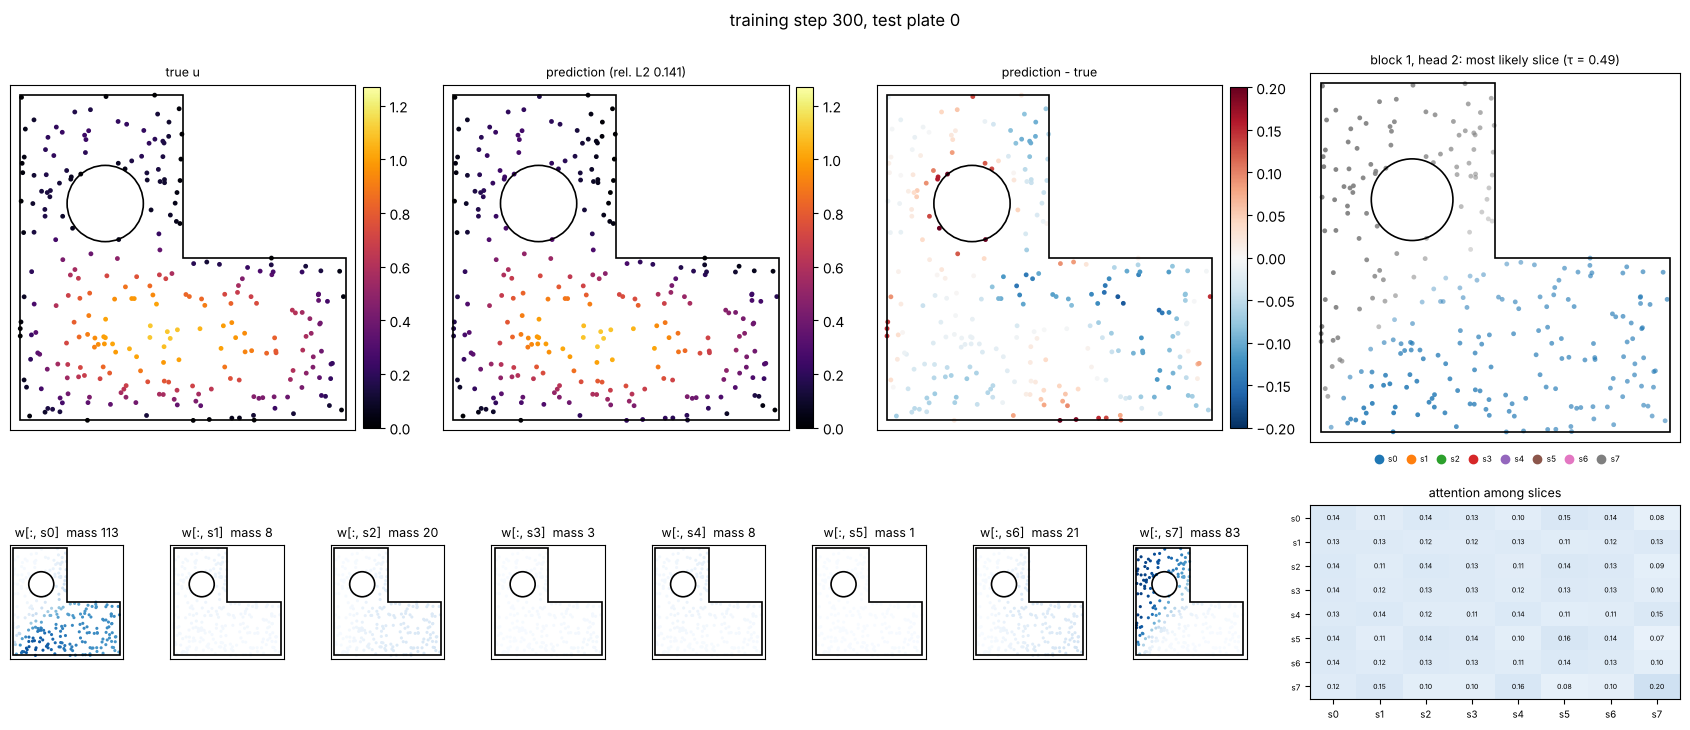

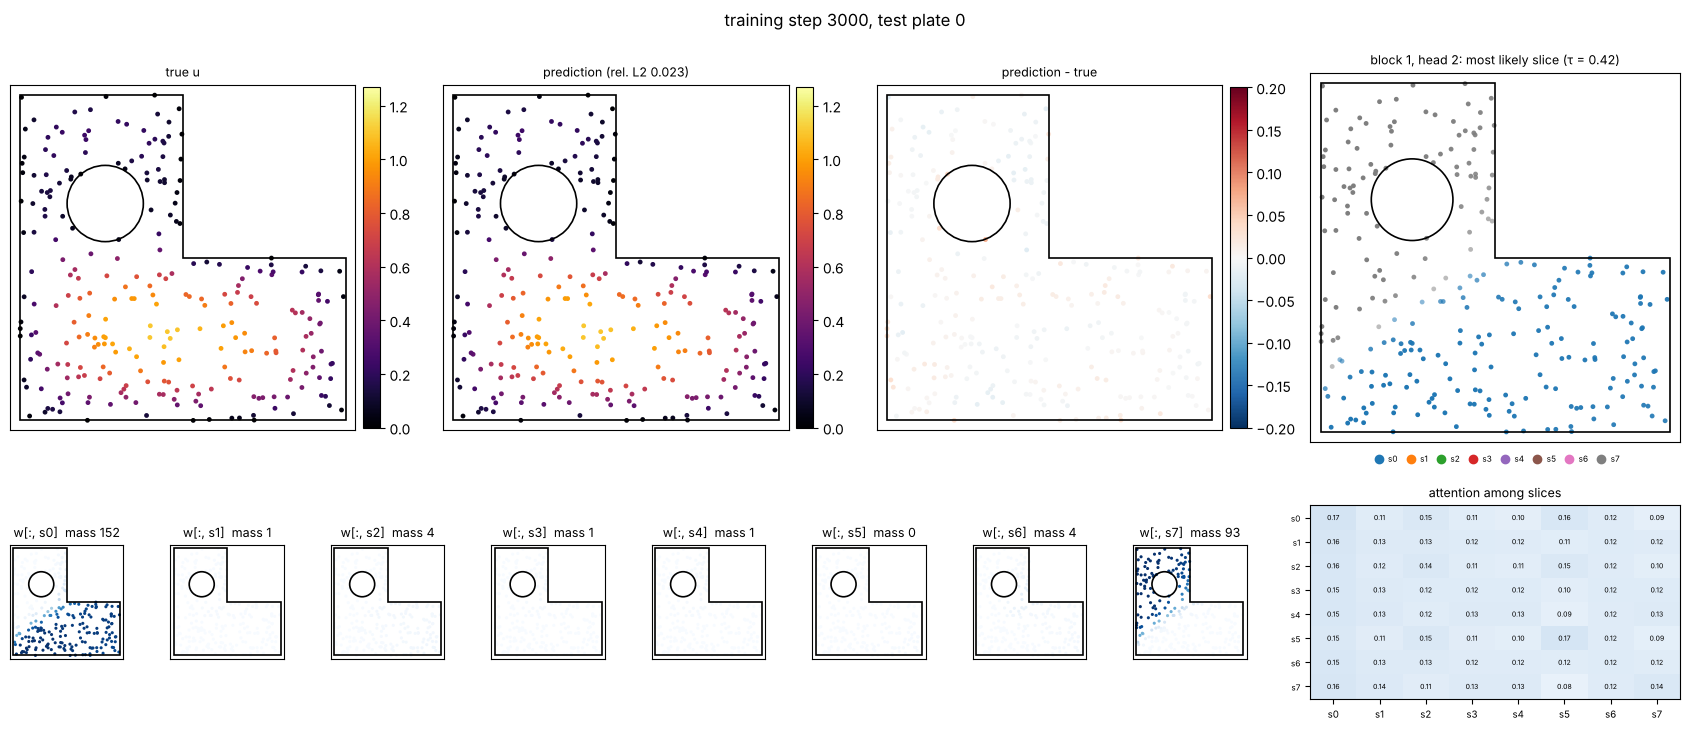

In [19]:
W_tr = jax.vmap(trace, in_axes=(None, 0))(params, F_test)
W_0 = jax.vmap(trace, in_axes=(None, 0))(params0, F_test)
def entropy(W):
    W = np.asarray(W)
    return float(np.mean(-(W * np.log(W + 1e-12)).sum(-1)) / np.log(cfg.slices))
ent = {(b, hd): (entropy(W_0.blocks[b]["w"][:, hd]), entropy(W_tr.blocks[b]["w"][:, hd]))
       for b in range(cfg.layers) for hd in range(cfg.heads)}
for (b, hd), (e0, e1) in ent.items():
    print(f"block {b + 1}, head {hd + 1}: entropy / log M  untrained {e0:.2f} -> trained {e1:.2f}")
blk, hd = min(ent, key=lambda bh: ent[bh][1])
print(f"\nsharpest: block {blk + 1}, head {hd + 1}")
for k in [0, 3, len(snapshots) - 1]:
    explore(k, 0, blk + 1, hd + 1)

### The trained head, with numbers

The same picture as section 4h, now with the trained weights, the same 32 points, and the sharpest head.

Two things to notice. The slice weights are now nearly one-hot: almost every point puts more than 0.9 on one
slice, and only two or three slices are used. And the attention matrix of this head is close to uniform (every
entry near 1/8), so every updated token $z'_m$ is about the same mix of all tokens. This head mostly broadcasts one
summary of the whole plate back to every point. Other heads attend more selectively; flip through them in the
explorer.

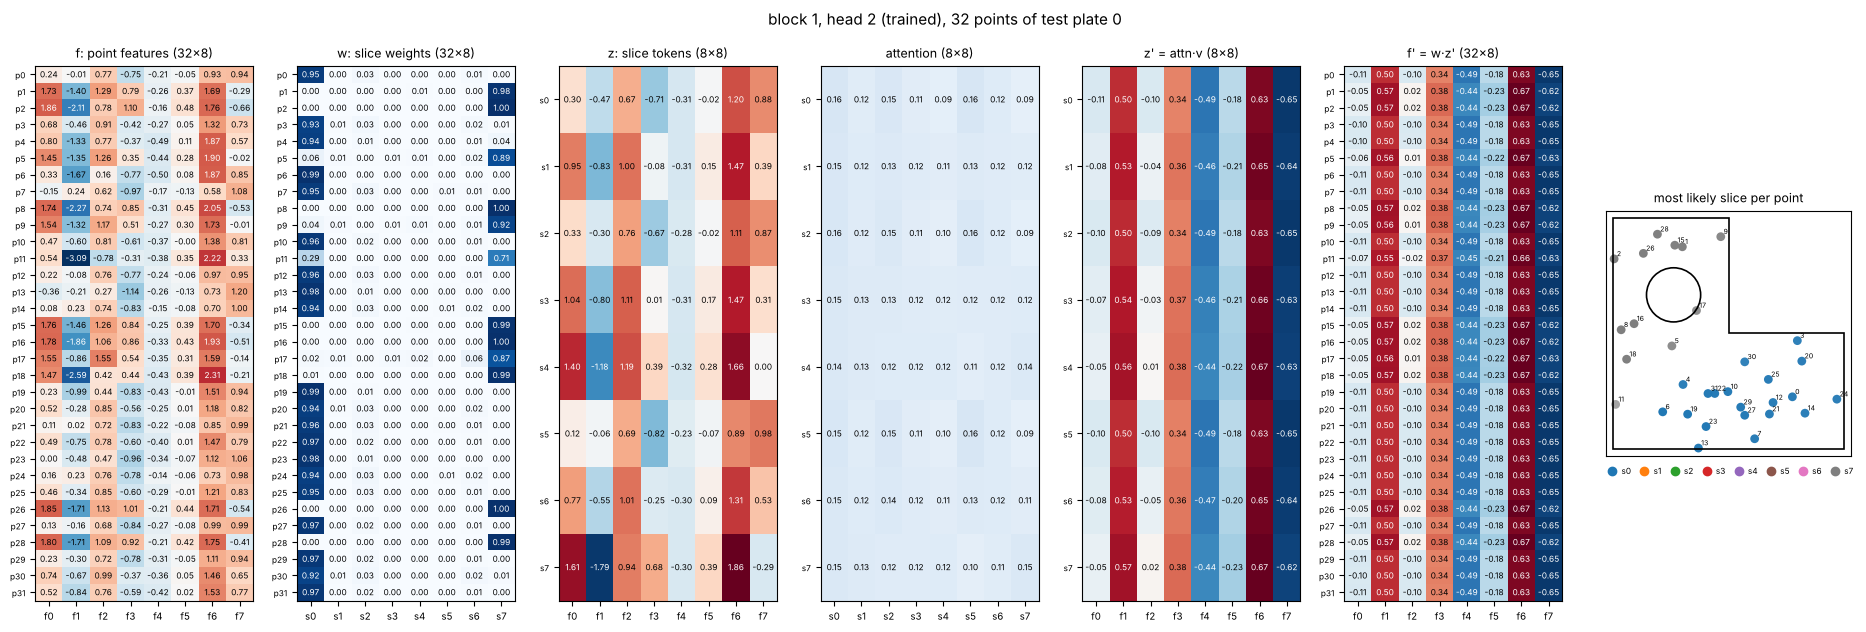

In [20]:
tr_trained = trace(params, F32)
viz.physics_attention_flow(tr_trained.blocks[blk], hd, pts32, hole0, f"block {blk + 1}, head {hd + 1} (trained), 32 points of test plate 0")
plt.show()

## 8. What did it learn?

### 8a. Predictions on plates it has never seen

Evaluated on dense clouds of 2000 points, eight times more than in training.

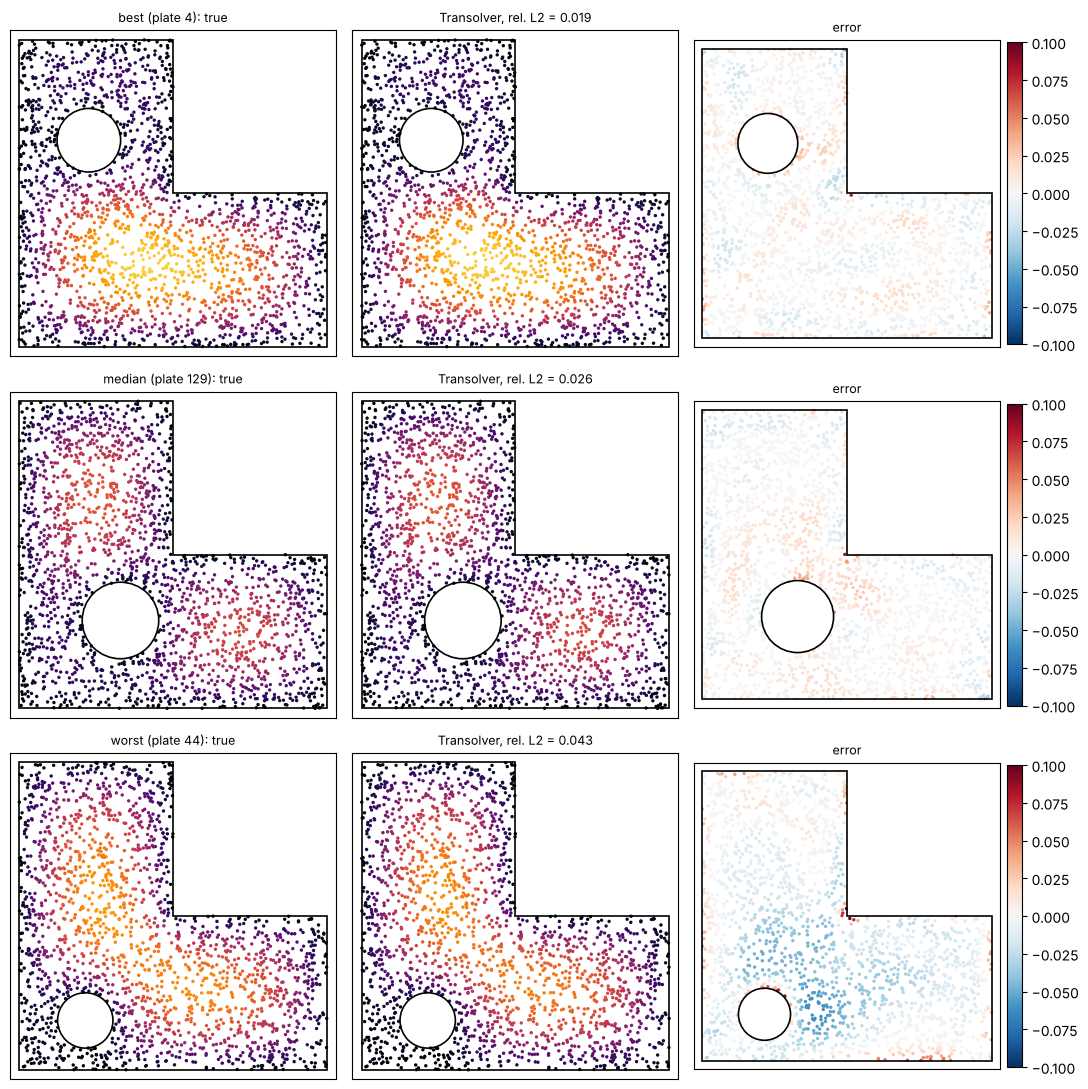

test relative L2 on 2000-point clouds: mean 0.0265, median 0.0258


In [21]:
dense = resample(test_set, 2000, seed=1, params=phys)
pred_dense = np.asarray(jax.vmap(trace, in_axes=(None, 0))(params, dense["features"]).output)
errs = np.asarray(relative_l2(pred_dense, dense["u"]))
order = np.argsort(errs)
picks = [order[0], order[len(order) // 2], order[-1]]
fig, axes = plt.subplots(3, 3, figsize=(11, 11))
for r, (i, tag) in enumerate(zip(picks, ["best", "median", "worst"])):
    pts, hole = dense["points"][i], test_set["hole"][i]
    viz.field(axes[r, 0], pts, dense["u"][i], hole, f"{tag} (plate {i}): true", 0, vmax, s=6)
    viz.field(axes[r, 1], pts, pred_dense[i], hole, f"Transolver, rel. L2 = {errs[i]:.3f}", 0, vmax, s=6)
    viz.field(axes[r, 2], pts, pred_dense[i] - dense["u"][i], hole, "error", -0.1, 0.1, cmap="RdBu_r", s=6, colorbar=True)
plt.tight_layout(); plt.show()
print(f"test relative L2 on 2000-point clouds: mean {errs.mean():.4f}, median {np.median(errs):.4f}")

The error is smooth and spread out, a few percent of the peak temperature, rather than concentrated at the hole.
On the worst plate the model underestimates the whole hot region a little: it gets the shape right and the level
slightly wrong.

### 8b. Are the slices physical states?

The paper's central claim (Sec. 3 and its Fig. 1): the learned slices group points that are in a **similar physical
state**, wherever they are, not points that are close together. On a car, one slice is the high-pressure front, one
the wake, and so on. Our study notes listed "are slices really physics?" as a fair discussion question. Here is
what this small model does. Below: every head of every block on two test plates, each point coloured by its most
likely slice.

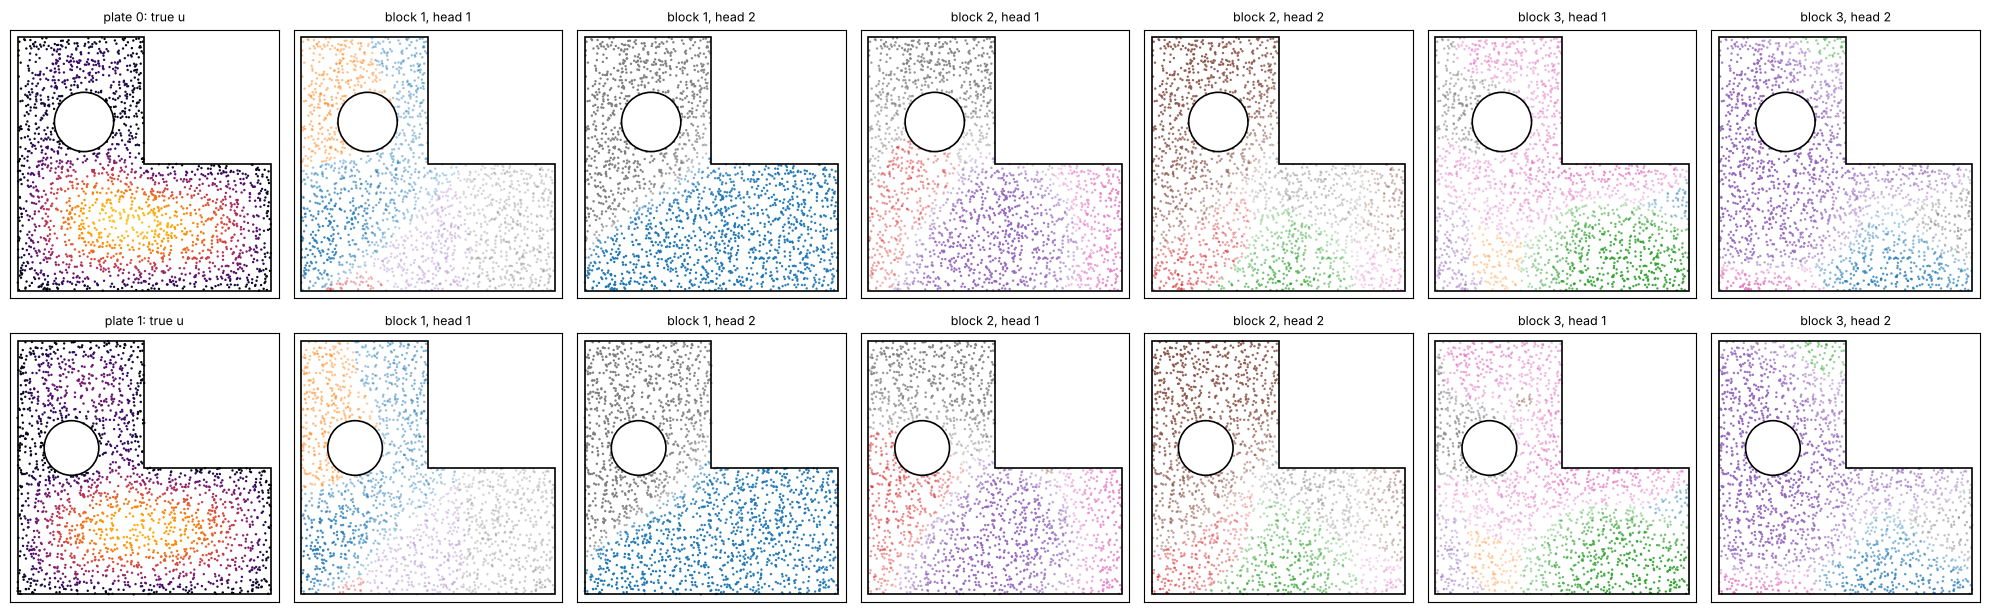

In [22]:
fig, axes = plt.subplots(2, 1 + cfg.layers * cfg.heads, figsize=(20, 6.4))
for r, i in enumerate([0, 1]):
    tr_i = trace(params, dense["features"][i])
    viz.field(axes[r, 0], dense["points"][i], dense["u"][i], test_set["hole"][i], f"plate {i}: true u", 0, vmax, s=3)
    for b in range(cfg.layers):
        for h_ in range(cfg.heads):
            viz.slice_map(axes[r, 1 + b * cfg.heads + h_], dense["points"][i], tr_i.blocks[b]["w"][h_],
                          test_set["hole"][i], f"block {b + 1}, head {h_ + 1}", s=3)
plt.tight_layout(); plt.show()

The slices look like **soft regions**: the upper arm, the lower arm, the corners, a band along an edge. They do not
obviously follow the isotherms, and they hardly change between the two plates even though the hole moved. To put a
number on "hardly": put 100 different holes into the plate, evaluate the model on the grid nodes that lie outside
all 100 holes (so the same points exist on every plate), and ask what fraction of the variation of $w_{im}$ comes
from changing the plate rather than from changing the point. 0 means the slices are fixed regions; 1 would mean
position does not matter at all.

In [23]:
rng_h = np.random.default_rng(123)
holes = [sample_hole(rng_h, phys) for _ in range(100)]
Xg, Yg = grid_xy(phys)
in_plate = free_mask(np.array([0.0, 0.0, 0.0]), phys)                     # the L without any hole
common = in_plate.copy()
for hl in holes:
    common &= np.hypot(Xg - hl[0], Yg - hl[1]) > hl[2]
pts_c = np.c_[Xg[common], Yg[common]]
feats_c = np.stack([make_features(pts_c, hl) for hl in holes]).astype(np.float32)
T_c = jax.vmap(trace, in_axes=(None, 0))(params, feats_c)
print(f"{common.sum()} grid nodes lie outside all 100 holes\n")
for b in range(cfg.layers):
    for h_ in range(cfg.heads):
        W_c = np.asarray(T_c.blocks[b]["w"][:, h_])                     # (plates, points, M)
        total = W_c.reshape(-1, cfg.slices).var(0).sum()
        across_plates = W_c.var(0).mean(0).sum()
        print(f"block {b + 1}, head {h_ + 1}: share of slice-weight variation due to the hole = {across_plates / total:.2f}")

1114 grid nodes lie outside all 100 holes



block 1, head 1: share of slice-weight variation due to the hole = 0.05
block 1, head 2: share of slice-weight variation due to the hole = 0.06
block 2, head 1: share of slice-weight variation due to the hole = 0.01
block 2, head 2: share of slice-weight variation due to the hole = 0.04
block 3, head 1: share of slice-weight variation due to the hole = 0.07
block 3, head 2: share of slice-weight variation due to the hole = 0.04


**What this says.** In this model the slice assignment is about 95% a function of position: the slices are a learned,
soft **domain decomposition** of the L, much like the "geometric gating" of GNOT, Transolver's predecessor. The hole
changes them only a little.

So how does the model know where the hole is? Through the **tokens**, not the assignment. A slice token is the
average of $f_i$ over the points in that slice, and $f_i$ depends on $d_i$, the distance to the hole. Move the hole
and the same slice gets a different average, attention mixes these averages, and deslicing sends the result back to
every point. Section 8d shows how much depends on this route.

Why not physical states, as in the paper? Plausible reasons, none proven here: in this problem position alone already
explains most of the field (the hot spot sits in whichever arm the hole leaves free); the model is tiny ($M = 8$, 3
blocks); and the paper's clearest examples are aerodynamic flows, where the same state (stagnation, wake, boundary
layer) really does appear in places that move with the geometry. It is a good question to bring to the
discussion: *the slices are learned, and nothing forces them to be physics.*

Note also how few slices carry mass in each head (explorer, bottom row). Unused slices are common; the paper says
$M$ between 32 and 256 is easy to tune and very large $M$ can hurt.

### 8c. Any number of points

Nothing in the model has size $N$: the embedding, MLPs and decoder act per point, and the slice tokens are averages.
So the model trained on 256 points runs on any cloud. This is Transolver's version of the FNO's zero-shot
super-resolution, and here it needs neither a grid nor the same points.

N =    32: test relative L2 = 0.0500


N =    64: test relative L2 = 0.0393


N =   128: test relative L2 = 0.0321


N =   256: test relative L2 = 0.0292


N =   512: test relative L2 = 0.0275


N =  1000: test relative L2 = 0.0267


N =  2000: test relative L2 = 0.0265


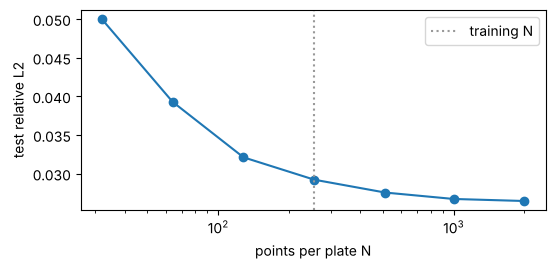

In [24]:
ns = [32, 64, 128, 256, 512, 1000, 2000]
errs_n = []
for n_eval in ns:
    d_n = resample(test_set, n_eval, seed=2, params=phys)
    errs_n.append(evaluate(params, d_n["features"], d_n["u"], cfg))
    print(f"N = {n_eval:5d}: test relative L2 = {errs_n[-1]:.4f}")
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.semilogx(ns, errs_n, "o-"); ax.axvline(256, color="0.6", ls=":", label="training N")
ax.set_xlabel("points per plate N"); ax.set_ylabel("test relative L2"); ax.legend(); plt.show()

The error is worst with very few points and keeps shrinking slowly as $N$ grows, even past the 256 points used in
training: the slice tokens are averages over the cloud, and with 32 points each average is noisy. More points,
better estimates of the same integrals.

### 8d. What if the model is not told where the hole is?

Train the same model with only $(x, y)$ per point, without the distance feature $d$. The geometry is then only
visible through **which points exist**: there are no points inside the hole. The only step that can notice that is
the slice aggregation, which averages over all the points, so the model has to infer the hole from those averages.

In [25]:
cfg_xy = cfg._replace(in_dim=2)
t0 = time.time()
params_xy, _, _, _ = train(init_params(jax.random.PRNGKey(1), cfg_xy), F_train[..., :2], u_train, cfg_xy,
                           n_steps=3000, batch_size=16, lr=3e-3, log_every=0)
print(f"trained in {time.time() - t0:.0f} s")
for n_eval in [64, 256, 2000]:
    d_n = resample(test_set, n_eval, seed=2, params=phys)
    e_xyd = evaluate(params, d_n["features"], d_n["u"], cfg)
    e_xy = evaluate(params_xy, d_n["features"][..., :2], d_n["u"], cfg_xy)
    print(f"N = {n_eval:5d}:  with d: {e_xyd:.4f}    without d: {e_xy:.4f}")

trained in 82 s


N =    64:  with d: 0.0393    without d: 0.3015


N =   256:  with d: 0.0292    without d: 0.1879


N =  2000:  with d: 0.0265    without d: 0.1296


Without $d$ the model still learns something (it beats the "average plate" baseline), but it is several times
worse, and **its error depends strongly on $N$**: with few points the hole is hard to locate from averages. This is
why practical Transolver setups feed geometry explicitly (signed distance, normals). It also shows that the slice
tokens really do aggregate information about the whole domain: that is the only route by which the missing points
inside the hole can affect the prediction.

## 9. Where is the physics?

Nowhere inside the network: no Laplacian, no boundary condition. The physics is in:

1. **the data**: every target was produced by the finite-difference solver of $-\Delta u = f$;
2. **the inputs**: $d$ tells each point where the cold hole is;
3. **the slice tokens**, averages over the whole plate that carry the geometry to every point (section 8b), and
   which the paper hopes, but does not force, to align with physical states.

So does the prediction satisfy the PDE? Evaluate the trained model on **every** free node of the $65 \times 65$ grid
(an "irregular cloud" that happens to be the full grid), and apply the same 5-point Laplacian the solver used.

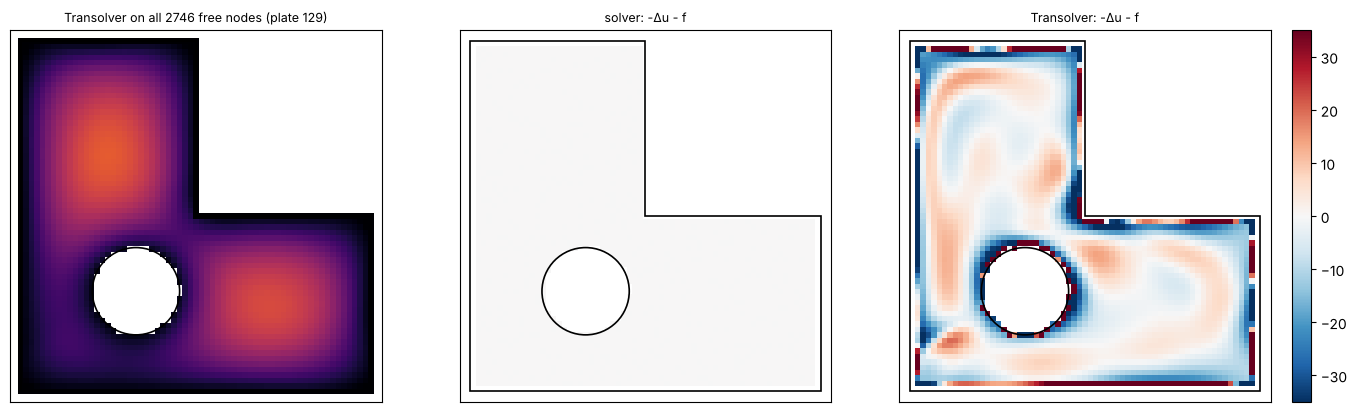

relative L2 of the field: 0.0213
PDE residual of the prediction: mean |−Δu − f| = 13.5  (f = 35.0)


In [26]:
i = int(order[len(order) // 2])
hole = test_set["hole"][i]
mask = free_mask(hole, phys)
X, Y = grid_xy(phys)
pts_all = np.c_[X[mask], Y[mask]]
u_pred = np.zeros_like(X); u_pred[mask] = np.asarray(apply(params, make_features(pts_all, hole).astype(np.float32), cfg))
u_true = test_set["u_grid"][i]
hgrid = 1 / (phys.n_grid - 1)
def residual(u):
    lap = (u[1:-1, 2:] + u[1:-1, :-2] + u[2:, 1:-1] + u[:-2, 1:-1] - 4 * u[1:-1, 1:-1]) / hgrid**2
    r = np.full_like(u, np.nan); r[1:-1, 1:-1] = -lap - phys.source
    return np.where(mask, r, np.nan)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
viz.grid_field(axes[0], u_pred, hole, f"Transolver on all {mask.sum()} free nodes (plate {i})", vmax)
for ax, u_, title in [(axes[1], u_true, "solver: -Δu - f"), (axes[2], u_pred, "Transolver: -Δu - f")]:
    im = ax.imshow(residual(u_), origin="lower", extent=(0, 1, 0, 1), cmap="RdBu_r", vmin=-phys.source, vmax=phys.source)
    viz.plate(ax, hole); ax.set_title(title, fontsize=9)
plt.colorbar(im, ax=axes[2], fraction=0.046)
plt.tight_layout(); plt.show()
r = residual(u_pred)[1:-1, 1:-1]
print(f"relative L2 of the field: {float(relative_l2(u_pred[mask], u_true[mask])):.4f}")
print(f"PDE residual of the prediction: mean |−Δu − f| = {np.nanmean(np.abs(r)):.1f}  (f = {phys.source})")

The solver's residual is zero to machine precision (it *is* the discrete equation). Transolver's field is within a
few percent of the solution, but its second derivatives are not: inside the plate the residual is a smooth pattern
of about ±40% of $f$, and it is largest on the nodes next to the edges and the hole, because the model never makes
$u$ exactly zero there (the boundary condition is only learned, not imposed). A small error in $u$ can be a large error in $\Delta u$. That is the gap a PINN-style loss
([02 Physics-informed NNs](../../../02-physics-informed-neural-networks/)) would close, at the price of needing
derivatives of the network; the Transolver paper uses no physics loss.

## 10. Transolver++ in one page, and FNO vs Transolver

**The problem Transolver++ (Luo et al., ICML 2025, [arXiv:2502.02414](https://arxiv.org/abs/2502.02414)) found.**
On huge meshes and in deep models the slice weights become **nearly uniform**: every point spreads its weight over all
slices, every token is about the average of the whole mesh, the tokens look alike, and attention among them
degenerates into average pooling ("homogeneous physical states"). The authors' fixes:

1. **Ada-Temp:** each point learns its own temperature, $\tau_i = \tau_0 + \mathrm{Linear}(x_i)$, instead of one per
   head. Where the physics changes quickly a point can commit sharply to one slice.
2. **Rep-Slice:** Gumbel-Softmax noise in the slice softmax, so the assignment behaves like a sampled, nearly one-hot
   choice that is still differentiable. The states stay distinct ("eidetic states").
3. **Parallelism:** a token is a sum over points, so each GPU sums over its own points and only the $M$ partial
   sums are exchanged, whatever the mesh size. With a lighter projection this reaches about 2.5M points.

How sharp are our slices? Section 7 measured it (entropy / $\log M$, 1 = uniform, 0 = one-hot). Here it is again
with the learned temperatures:

block 1, head 1: learned τ = 0.460   entropy / log M: untrained 0.58 -> trained 0.63
block 1, head 2: learned τ = 0.416   entropy / log M: untrained 0.67 -> trained 0.22
block 2, head 1: learned τ = 0.480   entropy / log M: untrained 0.65 -> trained 0.43
block 2, head 2: learned τ = 0.491   entropy / log M: untrained 0.35 -> trained 0.50
block 3, head 1: learned τ = 0.501   entropy / log M: untrained 0.60 -> trained 0.57
block 3, head 2: learned τ = 0.455   entropy / log M: untrained 0.81 -> trained 0.39


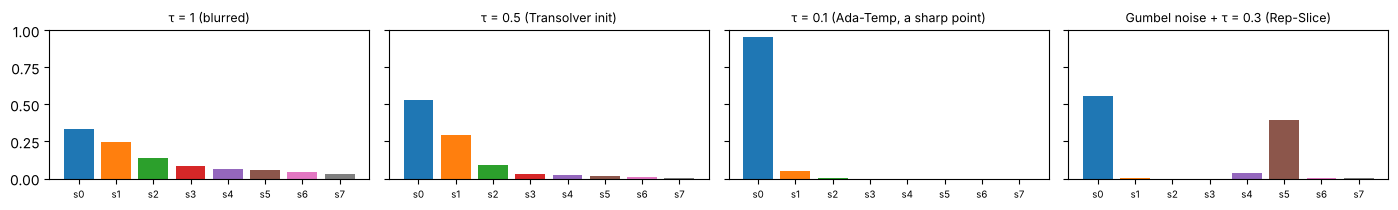

In [27]:
for (b, h_), (e0, e1) in ent.items():
    tau_b = float(jnp.exp(params["blocks"][b]["log_tau"][h_]))
    print(f"block {b + 1}, head {h_ + 1}: learned τ = {tau_b:.3f}   entropy / log M: untrained {e0:.2f} -> trained {e1:.2f}")

# The two Transolver++ knobs on one row of logits
logits = np.array([1.2, 0.9, 0.3, -0.2, -0.4, -0.5, -0.9, -1.1])
sm = lambda z: np.exp(z - z.max()) / np.exp(z - z.max()).sum()
gumbel = -np.log(-np.log(np.random.default_rng(0).uniform(size=8)))
fig, axes = plt.subplots(1, 4, figsize=(14, 2.2), sharey=True)
for ax, (wts, title) in zip(axes, [(sm(logits / 1.0), "τ = 1 (blurred)"), (sm(logits / 0.5), "τ = 0.5 (Transolver init)"),
                                   (sm(logits / 0.1), "τ = 0.1 (Ada-Temp, a sharp point)"), (sm((logits + gumbel) / 0.3), "Gumbel noise + τ = 0.3 (Rep-Slice)")]):
    ax.bar(range(8), wts, color=[viz.SLICE_COLORS[m] for m in range(8)]); ax.set_title(title, fontsize=9)
    ax.set_xticks(range(8)); ax.set_xticklabels(viz.slice_labels(8), fontsize=7)
plt.tight_layout(); plt.show()

On this small problem the picture is mixed: some heads become sharper during training, others stay about as soft
as at initialisation or even soften, and the single temperature per head stays close to 0.5. A soft head is not useless (it
can mix information broadly), but it hints at the effect Transolver++ fixes: one temperature for all points cannot
make some points commit sharply while others stay mixed. Ada-Temp gives each point its own. The really
homogeneous states appear on meshes four orders of magnitude larger and in deeper models.

### FNO vs Transolver, side by side

| | FNO ([`fno/`](../../fno/)) | Transolver (this folder) |
|---|---|---|
| input | values on a uniform grid | any point cloud or mesh, any order |
| global step | FFT → keep $k_{max}$ modes → $R$ → inverse FFT | slice → $M$ tokens → attention → deslice |
| what the global step "is" | a convolution, kernel $\kappa(x - y)$ | a low-rank kernel $\kappa(x, y) = \sum_{m,m'} w_m(x)\, A_{mm'}\, \tilde w_{m'}(y)$ that depends on the state at $x$ and $y$ |
| tokens | Fourier modes (fixed basis) | slices (learned from the data, input dependent) |
| cost per layer | $O(N \log N)$ | $O(N M)$ |
| geometry | rectangle or torus; anything else needs masks or a mapping | built in: points and their features |
| resolution change | evaluate on a finer grid | evaluate on more (or different) points |
| physics in the loss | no | no |

Both learn the solution operator from solver data, and both are a kernel integral operator in disguise. The FNO
fixes the basis (Fourier waves) and needs the grid that makes it cheap. Transolver **learns** the basis (the slices)
from the data, and that is what frees it from the grid.